# Notebook 01 — Variable establishment and mapping

**Thesis:** *Where Cyclists Ride and Why — A Stress-Weighted Demand Model for the Sydney CBD*

For **every directed edge** of the City of Sydney cycling network this notebook builds the input variables
the **Furth v2.2** Level-of-Traffic-Stress (LTS) criteria need, and writes a single hand-off file,
`edges_with_variables.gpkg`, which Notebook 02 classifies and Notebook 04 routes on.

| Section | Column(s) | What it is |
|---------|-----------|-----------|
| B.1 | `hw` | OSM road class — the Furth branch selector |
| B.2 | `speed_kmh`, `speed_source` | prevailing speed, km/h (Compass GPS p85 → TfNSW signposted → OSM `maxspeed` → NSW statutory default) |
| B.3–B.7 | `lanes_per_dir`, `is_oneway`, `has_centreline`, `lane_category` | Furth mixed-traffic row selectors |
| B.8 | `facility_type` | `track` / `lane_no_park` / `lane_with_park` / `mixed` / `excluded` |
| B.9–B.12 | `bike_lane_width_ft`, `parking`, `bike_lane_reach_ft`, `adt` | bike-lane geometry (feet), adjacent parking, motor ADT |
| A.6 | `grade`, `grade_abs` | signed longitudinal gradient (%) |

Run top-to-bottom after editing the **CONFIG** cell. The Compass GPS speed layer can be switched off with
`USE_COMPASS_SPEED` at the top of Section A.2.


## Pipeline at a glance

```mermaid
flowchart TD
    OSM[OSM network via OSMnx] --> LINKID[A1b: undirected link_id]
    GPS[Sydney_stats.csv Compass GPS p85] --> SPD[B2: speed_kmh]
    ZONE[TfNSW Speed Zones] --> SPD
    OSMMAX[OSM maxspeed] --> SPD
    DEF[NSW statutory default] --> SPD
    TVV[TfNSW Traffic Volume Viewer] --> ADT[B12: adt]
    DEM[ELVIS 1 m DEM] --> GRADE[A6: grade / grade_abs]
    OSM --> B0[B0: absorb parallel paths]
    B0 --> FAC[B8: facility_type]
    SPD --> LTSVARS[Furth v2.2 input table]
    ADT --> LTSVARS
    GRADE --> LTSVARS
    FAC --> LTSVARS
    LTSVARS --> OUT[(edges_with_variables.gpkg)]
    OUT --> NB02[Notebook 02: LTS classification]
```

**Speed priority is a data-quality order, not highest-wins:** Compass GPS p85 → TfNSW signposted →
OSM `maxspeed` → NSW statutory default. The last two are last resorts.


## Key conventions

- **CRS:** every layer is reprojected to **EPSG:28356** (GDA94 / MGA Zone 56) so distances are in metres.
- **Speed bands are Furth-native.** Furth v2.2 publishes its mixed-traffic columns in **mph**; those column
  edges are converted once to km/h (×1.609344) and read directly — one source of truth for the thresholds.
- **LTS is per physical link; gradient is per direction.** Stress is one value shared by both directed
  edges of a link; grade keeps its sign for each direction.
- **Conservative when unobserved:** an untagged lane width reads as narrow, and unknown parking reads as present.


# 0 — Setup


## 0.1 Environment and imports

Loads the spatial/tabular/plotting stack and prints the package versions actually in use.


In [2]:
# Import standard library modules for OS interactions, pattern matching, math, and date handling
import os, re, math
from pathlib import Path
from datetime import datetime

# Import core numerical and spatial data processing libraries
import numpy as np
import pandas as pd
import geopandas as gpd

# Import Matplotlib modules for plotting, legend customisation, and color mapping
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import Normalize
import matplotlib.cm as cm

# Confirm successful import and display package versions
print("Imports OK —",
      f"pandas {pd.__version__}, geopandas {gpd.__version__}, numpy {np.__version__}")

Imports OK — pandas 3.0.2, geopandas 1.1.3, numpy 2.4.4


## 0.2 Build the study-area cordon

Reads the 2016 ABS SA1 polygons from their zip, keeps the SA1s in the cordon list, dissolves them into a
single boundary, and writes `study_area_cordon.gpkg` (metric CRS) — the spatial anchor for every
downstream notebook. Run once, or whenever the cordon list changes.


In [3]:
# ─────────────────────────────────────────────────────────────
# 0.2 — BUILD study_area_cordon.gpkg from ABS SA1 polygons + cordon list
# Run ONCE (or whenever the cordon list changes). Reads the ABS 2016 SA1
# shapefile straight from its zip, keeps only the SA1s in the cordon CSV,
# dissolves them into one polygon, and writes the gpkg that CONFIG loads.
# ─────────────────────────────────────────────────────────────
import geopandas as gpd, pandas as pd
from pathlib import Path

PROJECT_ROOT   = Path(os.getcwd())

DATA_RAW       = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
FIGURES        = PROJECT_ROOT / "figures"
REPORTS        = PROJECT_ROOT / "reports"
for f in (DATA_RAW, DATA_PROCESSED, FIGURES, REPORTS):
    f.mkdir(parents=True, exist_ok=True)

# --- paths (edit to match your machine) ---
SA1_ZIP     = PROJECT_ROOT / DATA_RAW / "1270055001_sa1_2016_aust_shape.zip"
CORDON_CSV  = PROJECT_ROOT / DATA_RAW / "SA1s_in_Boundary_Cordon.csv"
CORDON_OUT  = PROJECT_ROOT / DATA_RAW / "study_area_cordon.gpkg"
METRIC_CRS  = "EPSG:28356"
CORDON_OUT.parent.mkdir(parents=True, exist_ok=True)

print("[A0] Building study-area cordon...")

# --- 1. the list of SA1s inside the cordon ---
clist = pd.read_csv(CORDON_CSV, dtype=str)
want_main = set(clist["SA1_MAIN16"].str.strip())      # 11-digit (globally unique)
want_7dig = set(clist["SA1_7DIG16"].str.strip())      # 7-digit fallback
print(f"  Cordon list: {len(want_main):,} SA1s across "
      f"{clist['SA2_NAME16'].nunique()} SA2s")

# --- 2. ABS SA1 polygons, read directly from the zip ---
#     GeoPandas/Fiona reads a zipped shapefile via the zip:// prefix — no manual unzip.
sa1 = gpd.read_file(f"zip://{SA1_ZIP}")
print(f"  ABS SA1 polygons loaded: {len(sa1):,}")

# ABS code columns can arrive as float/int and lose leading zeros — force clean strings.
def _clean(col):
    return (col.astype("Int64").astype(str).str.strip()
            if pd.api.types.is_numeric_dtype(col)
            else col.astype(str).str.strip())
for c in ("SA1_MAIN16", "SA1_7DIG16"):
    if c in sa1.columns:
        sa1[c] = _clean(sa1[c])

# --- 3. keep only the cordon SA1s (match on 11-digit, fall back to 7-digit) ---
mask = sa1["SA1_MAIN16"].isin(want_main)
if mask.sum() < len(want_main) and "SA1_7DIG16" in sa1.columns:
    mask = mask | sa1["SA1_7DIG16"].isin(want_7dig)
keep = sa1[mask].copy()
print(f"  Matched {len(keep):,} of {len(want_main):,} cordon SA1s")
missing = want_main - set(keep["SA1_MAIN16"])
if missing:
    print(f"  ! {len(missing)} SA1s not found in shapefile (first few: "
          f"{sorted(missing)[:5]}) — check the code columns")

# --- 4. dissolve to a single cordon polygon, project to metres, write gpkg ---
cordon = keep.to_crs(METRIC_CRS).dissolve()[["geometry"]]
cordon["name"] = "study_area_cordon"
if CORDON_OUT.exists():
    CORDON_OUT.unlink()          # drop any stale multi-layer file
cordon.to_file(CORDON_OUT, layer="study_area_cordon", driver="GPKG")
print(f"  Saved: {CORDON_OUT}")
print(f"  Cordon area: {cordon.geometry.area.iloc[0]/1e6:.2f} km²")

[A0] Building study-area cordon...
  Cordon list: 556 SA1s across 13 SA2s
  ABS SA1 polygons loaded: 57,523
  Matched 556 of 556 cordon SA1s
  Saved: c:\Users\aylex\OneDrive - The University of Sydney (Students)\Thesis A\Python Code\Phase 1 + 2\data\raw\study_area_cordon.gpkg
  Cordon area: 37.11 km²


## 0.3 Configuration

All tunable paths and parameters in one place: the pinned OSM snapshot, CRS, the Furth speed-band edges
(mph→km/h), and the speed/parking/ADT/grade processing constants. The Compass GPS speed layer itself is
toggled at the top of Section A.2 (`USE_COMPASS_SPEED`).


In [4]:
# ─────────────────────────────────────────────────────────────
# CONFIG  (run the notebook from the project root)
# ─────────────────────────────────────────────────────────────

RUN_STAMP = datetime.now().strftime("%Y%m%d_%H%M")

# ── Input files ───────────────────────────────────────────────
SPEED_FILE      = DATA_RAW / "Sydney_stats.csv"            # GPS p85 probe speeds
SPEED_ZONES_SHP = DATA_RAW / "nsw_speed_zones.shp" / "Speed_Zones.shp"
TVV_GLOB        = "Traffic_Volume_Viewer_-_*_Data.csv"     # motor ADT, yearly
FRESHNESS_FILE  = DATA_RAW / "osm_way_timestamps.csv"      # OSM edit dates (cache)
DEM_FILE        = DATA_RAW / "sydney_elvis_dem.tif"        # ELVIS gradient
ELVIS_TILE_DIR  = DATA_RAW / "elvis_tiles"
CORDON_FILE     = DATA_RAW / "study_area_cordon.gpkg"      # SA1 cordon (study area)

# ── CRS ───────────────────────────────────────────────────────
METRIC_CRS = "EPSG:28356"        # GDA94 / MGA Zone 56 (metres)

# ── OSM download control ──────────────────────────────────────
CORDON_BUFFER_M = 500   # download margin so boundary edges stay connected
FORCE_REFRESH   = False # True = download a NEW snapshot (changes every downstream result)
OSM_SNAPSHOT    = "osm_network_20261023.graphml"   # pinned network vintage for the final run
GRADE_ZERO_RULE = "dem_unreliable"   # "dem_unreliable" (final) | "legacy" (zero all path/footway)
OSM_RETRIES     = 3

# ══════════════════════════════════════════════════════════════
# SPEED BANDS — single source of truth = Furth v2.2 native (mph→km/h)
# ══════════════════════════════════════════════════════════════
# Furth's "Bikes in mixed traffic" table columns, in mph, are:
#   0–23.5 | 23.5–28.5 | 28.5–33.5 | 33.5–38.5 | 38.5–43.5 | 43.5–48.5 | 48.5+
# The km/h column edges are derived from Furth's mph edges by conversion (x1.609344),
MPH_TO_KMH = 1.609344
FURTH_MPH_EDGES = [23.5, 28.5, 33.5, 38.5, 43.5, 48.5]
FURTH_KMH_EDGES = [round(m * MPH_TO_KMH, 2) for m in FURTH_MPH_EDGES]
# -> [37.82, 45.87, 53.91, 61.96, 70.01, 78.05]

# Reporting-only coarse band (low/mod/high/highest) for the diagnostic maps below.
# These are NOT used to classify LTS (NB02 reads speed_kmh against the full Furth
# columns). They only colour the maps so the speed layer is legible.
SPEED_LOW_MAX  = FURTH_KMH_EDGES[0]   # 37.82  (<= 23.5 mph)
SPEED_MOD_MAX  = FURTH_KMH_EDGES[2]   # 53.91  (<= 33.5 mph)
SPEED_HIGH_MAX = FURTH_KMH_EDGES[3]   # 61.96  (<= 38.5 mph)

def speed_band(kmh):
    """Coarse reporting band for the diagnostic maps (NOT the LTS classifier)."""
    if kmh is None:            return "unknown"
    if kmh <= SPEED_LOW_MAX:   return "low"
    if kmh <= SPEED_MOD_MAX:   return "moderate"
    if kmh <= SPEED_HIGH_MAX:  return "high"
    return "highest"

# ── GPS speed cleaning ────────────────────────────────────────
SPEED_DUP_AGG = "max"    # duplicate osmids: 'max' (conservative) or 'mean'
GPS_P80_MIN   = 1.0      # drop garbage probe rows outside this range
GPS_P90_MAX   = 130.0

# ── Speed-zone overlay ────────────────────────────────────────
SPEED_MATCH_BUFFER_M = 25     # edge within this of a zone can take its speed
SPEED_MIN_OVERLAP    = 0.30   # ... if >=30% of the edge lies in the zone buffer

# ── Bike-lane geometry (Furth tables are in feet) ─────────────
DEFAULT_BIKE_LANE_WIDTH_FT = 5.0   # Austroads 1.5 m desirable min -> reads "narrow"
PARKING_STALL_FT           = 6.5   # ~2.0 m kerbside stall

# ── Parking defaults (3-value: yes / no / unknown) ────────────
# tertiary/secondary default to 'unknown', then unknown -> 'yes' for LTS.
# Treating unknown parking as 'yes' is the conservative choice (assumes a door-zone conflict).
PARKING_CLASS_DEFAULT = {
    "residential":"yes","living_street":"yes","service":"yes","unclassified":"no",
    "tertiary":"yes","tertiary_link":"no",
    "secondary":"no","secondary_link":"no",
    "primary":"no","primary_link":"no","trunk":"no","trunk_link":"no",
    "motorway":"no","motorway_link":"no",
    "cycleway":"no","footway":"no","path":"no","pedestrian":"no",
}
PARKING_UNKNOWN_AS = "yes"   # conservative: treat unknown as present for LTS

# ── Facility consistency across a physical link ───────────────
FACILITY_LINK_RULE = "direction_specific"  # or "worst"

# ── Motor ADT (vehicles only) ─────────────────────────────────
ADT_ON_LINK_M         = 30    # counter this close = ON the link
ADT_SAME_TYPE_M       = 500   # else borrow nearest same-class counter within this
ADT_STATION_TO_EDGE_M = 75    # radius to label a station with an OSM class
ADT_MIN_STATIONS      = 3     # a class needs this many stations for a class average
ADT_REFERENCE_YEAR    = 2025
ADT_GROWTH_METHOD     = "per_class"   # 'per_class' | 'constant' | 'none'
ADT_MOTOR_ANNUAL_GROWTH = 0.0

# ── Count aggregation (set for downstream notebooks; NB01 does not use counts) ──
COUNT_AM_COLS        = ["Time_0600","Time_0700","Time_0800"]
COUNTS_BIDIRECTIONAL = True

VALIDATION_SEED = 42

print("="*64)
print("CONFIG — Notebook 01 (rewrite)")
print(f"  CRS                : {METRIC_CRS}")
print(f"  Furth mph edges    : {FURTH_MPH_EDGES}")
print(f"  -> km/h edges      : {FURTH_KMH_EDGES}")
print(f"  Reporting low<=    : {SPEED_LOW_MAX} km/h")
print(f"  ADT reference year : {ADT_REFERENCE_YEAR}  (growth: {ADT_GROWTH_METHOD})")
print(f"  Facility link rule : {FACILITY_LINK_RULE}")
print(f"  Run stamp          : {RUN_STAMP}")
print("="*64)

CONFIG — Notebook 01 (rewrite)
  CRS                : EPSG:28356
  Furth mph edges    : [23.5, 28.5, 33.5, 38.5, 43.5, 48.5]
  -> km/h edges      : [37.82, 45.87, 53.91, 61.96, 70.01, 78.05]
  Reporting low<=    : 37.82 km/h
  ADT reference year : 2025  (growth: per_class)
  Facility link rule : direction_specific
  Run stamp          : 20261104_2112


# A — Load the network and all data layers


## A.1 OSM network (pinned snapshot)

Extends the OSMnx tag set to pull cycleway/lane/parking/speed attributes and loads the routable graph over
the cordon + 500 m buffer. Uses the pinned snapshot for reproducibility (falling back to a cached file or a
fresh Overpass download only if asked), and checks the extent covers the cordon on every side.


In [5]:
import osmnx as ox
import time as _t

print("[A1] OSM network...")

# --- 1. Extend OSMnx default tag settings to pull specialised bicycle, lane, speed, and structural attributes ---
ox.settings.useful_tags_way = sorted(set(ox.settings.useful_tags_way + [
    "cycleway","cycleway:both","cycleway:left","cycleway:right",
    "cycleway:width","cycleway:left:width","cycleway:right:width",
    "cycleway:both:lane","cycleway:left:lane","cycleway:right:lane","cycleway:lane",
    "cycleway:buffer","cycleway:separation",
    "parking:both","parking:left","parking:right",
    "parking:lane:both","parking:lane:left","parking:lane:right","parking:both:restriction",
    "bicycle","designation","informal","foot","surface",
    "lanes","lanes:forward","lanes:backward",
    "maxspeed","maxspeed:forward","maxspeed:backward",
    "width","est_width","oneway","oneway:bicycle","junction","access","service",
    "motor_vehicle","traffic_calming","segregated","sidewalk","sidewalk:bicycle",
    "name","tunnel","bridge","layer",
]))
ox.settings.useful_tags_node = sorted(set(getattr(ox.settings,"useful_tags_node",[]) + [
    "highway","crossing","traffic_signals","stop","give_way","traffic_calming",
]))

# --- 2. Build download bounding polygon with buffer margin in EPSG:4326 (WGS84) ---
_cordon = gpd.read_file(CORDON_FILE, layer="study_area_cordon").to_crs(METRIC_CRS).dissolve()
CORDON_POLY_M  = _cordon.geometry.iloc[0]
CORDON_POLY_DL = (gpd.GeoSeries([CORDON_POLY_M.buffer(CORDON_BUFFER_M)], crs=METRIC_CRS)
                  .to_crs("EPSG:4326").iloc[0])
CORDON_DESC = f"SA1 cordon + {CORDON_BUFFER_M} m buffer"

# Helper function to find the most recent GraphML network file in the raw data directory
def _latest_graphml():
    xs = sorted(DATA_RAW.glob("osm_network_*.graphml"))
    return xs[-1] if xs else (DATA_RAW / "osm_network.graphml")

graphml_path = DATA_RAW / f"osm_network_{datetime.now().strftime('%Y%m%d')}.graphml"
prev = _latest_graphml()

# --- 3. Load pinned snapshot or download fresh network with retry fallback logic ---
if (not FORCE_REFRESH) and (DATA_RAW / OSM_SNAPSHOT).exists():
    # Use pinned snapshot to ensure 100% downstream reproducibility
    graphml_path = DATA_RAW / OSM_SNAPSHOT
    print(f"  FORCE_REFRESH=False — using pinned snapshot {graphml_path.name}")
    G = ox.load_graphml(str(graphml_path))
elif not FORCE_REFRESH:
    raise FileNotFoundError(f"Pinned snapshot {OSM_SNAPSHOT} not in {DATA_RAW}. Set OSM_SNAPSHOT to the "
                            f"file you want, or FORCE_REFRESH=True to download (results will change).")
else:
    # Attempt downloading fresh network via OSMnx Overpass API query
    G = None
    for attempt in range(1, OSM_RETRIES + 1):
        try:
            print(f"  Download attempt {attempt}/{OSM_RETRIES}: {CORDON_DESC}")
            G = ox.graph_from_polygon(CORDON_POLY_DL, network_type="all", retain_all=True)
            ox.save_graphml(G, filepath=str(graphml_path))
            print(f"  Saved {graphml_path.name}")
            break
        except Exception as e:
            print(f"    failed: {type(e).__name__}: {e}")
            _t.sleep(2 ** attempt)
    # Fallback to local file if API download fails
    if G is None:
        if prev.exists():
            print(f"  All attempts failed — falling back to {prev.name}")
            G = ox.load_graphml(str(prev))
        else:
            raise RuntimeError("OSM download failed and no saved graphml to fall back to.")

# Record active network vintage filename for downstream validation
(DATA_PROCESSED / "osm_snapshot.txt").write_text(graphml_path.name)
print(f"  network vintage recorded: {graphml_path.name}")

# Convert NetworkX graph to GeoDataFrames
nodes, edges = ox.graph_to_gdfs(G)
print(f"  Edges: {len(edges):,}  Nodes: {len(nodes):,}")

# --- 4. Spatial coverage check: ensure network bounds span the study area boundary ---
_nx = np.array([d["x"] for _, d in G.nodes(data=True)])
_ny = np.array([d["y"] for _, d in G.nodes(data=True)])
_nb = (gpd.GeoSeries(gpd.points_from_xy(_nx, _ny), crs="EPSG:4326")
       .to_crs(METRIC_CRS).total_bounds)
_cb = CORDON_POLY_M.bounds

# Verify network extent extends beyond study area by at least 250 m margin
_short = {s: round(g) for s, g in
          [("west", _nb[0]-_cb[0]), ("south", _nb[1]-_cb[1]),
           ("east", _cb[2]-_nb[2]), ("north", _cb[3]-_nb[3])] if g > 250}
assert not _short, (f"Network falls short of cordon by (m): {_short} — "
                    f"wrong gpkg layer, or SA1 list missing western zones?")
print("  Coverage OK — network spans the cordon on every side "
      f"(download margin = {CORDON_BUFFER_M} m)")

[A1] OSM network...
  FORCE_REFRESH=False — using pinned snapshot osm_network_20261023.graphml
  network vintage recorded: osm_network_20261023.graphml
  Edges: 97,818  Nodes: 34,769
  Coverage OK — network spans the cordon on every side (download margin = 500 m)


### A.1.1 Cordon flag

Flags each edge as inside the core cordon or in the 500 m download buffer. Buffer edges are kept so
boundary connections stay intact for routing, while downstream analysis can isolate the true study area.


In [6]:
# Reproject edge geometries to the project metric CRS (EPSG:28356) for spatial intersection
_em = edges.to_crs(METRIC_CRS)

# Flag edges as True if they intersect the core study area cordon polygon
edges["in_cordon"] = _em.geometry.intersects(CORDON_POLY_M).values

# Print summary count of edges strictly within the study area versus the outer buffer margin
print(f"  In cordon: {edges.in_cordon.sum():,} of {len(edges):,} edges "
      f"(rest = {CORDON_BUFFER_M} m buffer)")

  In cordon: 80,180 of 97,818 edges (rest = 500 m buffer)


### A.1.2 Undirected link IDs

Builds a canonical `link_id` per edge by sorting its endpoint node IDs, so the two directions of a two-way
road map to one physical link — needed for link-level attributes and to avoid double-sampling in validation.


In [7]:
print("[A1.2] Undirected link IDs...")

# Helper function to generate an undirected canonical ID for a physical road link
def _make_link_id(idx):
    u, v, key = idx
    # Sort node IDs (min, max) so opposite directions of a two-way road map to the same tuple ID
    return (min(u, v), max(u, v), key)

# Assign canonical link IDs across all directed edges in the network index
edges["link_id"] = [_make_link_id(idx) for idx in edges.index]

# Calculate totals for directed edges versus unique physical road links
n_edges, n_links = len(edges), edges["link_id"].nunique()

# Print link grouping summary statistics
print(f"  Directed edges     : {n_edges:,}")
print(f"  Unique phys. links : {n_links:,}")
print(f"  Two-way duplicates : {n_edges - n_links:,}")

[A1.2] Undirected link IDs...
  Directed edges     : 97,818
  Unique phys. links : 52,986
  Two-way duplicates : 44,832


### A.1.3 Tag-cleaning helper (`safe_str`)

Normalises any OSM tag value (lists, nulls, NaN, numbers) into a clean lowercase string for safe comparisons.


In [8]:
def safe_str(val):
    """Any OSM tag value -> clean lowercase string."""
    # Return empty string for missing or None values
    if val is None:
        return ""
    # Return empty string for missing floating-point values (NaN)
    if isinstance(val, float) and np.isnan(val):
        return ""
    # Extract the first element if the tag value is stored as a list (e.g., combined OSM ways)
    if isinstance(val, list):
        val = val[0] if val else ""
    # Convert value to string, cast to lowercase, and strip leading/trailing whitespace
    return str(val).lower().strip()

print("safe_str() ready")

safe_str() ready


## A.2 Compass GPS speed probes

Loads the Compass IoT GPS probe speeds, drops garbage rows, computes a p85 operating speed per OSM way
(midpoint of p80 and p90), aggregates duplicates conservatively (max), and builds the `speed_lookup`.

**Toggle:** set `USE_COMPASS_SPEED = False` at the top of this cell to disable the GPS layer entirely; the
speed hierarchy in B.2 then falls back to TfNSW signposted → OSM `maxspeed` → NSW statutory default.


In [9]:
# ── Compass GPS speed layer (TOGGLE) ──────────────────────────────────────────
# The Compass IoT GPS p85 probe speeds are the top source in the B.2 speed hierarchy. Set this False to
# disable the layer entirely: speed_lookup is left empty, every edge gets NaN gps speed in A.3, and B.2
# falls back to TfNSW signposted -> OSM maxspeed -> NSW statutory default (no edge will read 'gps_p85').
USE_COMPASS_SPEED = True

print("[A.2] GPS speed...")

if not USE_COMPASS_SPEED:
    # Layer disabled: skip loading entirely and hand B.2 an empty lookup.
    speed_lookup = {}
    print("  Compass GPS speed layer DISABLED (USE_COMPASS_SPEED=False) — "
          "speeds will fall back to TfNSW -> OSM -> NSW default.")
else:
    # Require the probe-speed file before reading it.
    if not SPEED_FILE.exists():
        raise FileNotFoundError(f"Required speed file not found: {SPEED_FILE}")

    speed_df = pd.read_csv(SPEED_FILE)

    # The file must carry the osmid and the p80/p90 percentile speeds.
    for c in ("osmid","p80","p90"):
        if c not in speed_df.columns:
            raise KeyError(f"Speed file missing '{c}'. Found: {list(speed_df.columns)}")

    # Drop NaNs and out-of-range probe rows.
    n0 = len(speed_df)
    speed_df = speed_df[(speed_df["p80"] > GPS_P80_MIN) & (speed_df["p90"] < GPS_P90_MAX)]
    speed_df = speed_df.dropna(subset=["p80","p90"])
    print(f"  Dropped {n0-len(speed_df):,} garbage/NaN rows")

    # p85 operating speed = midpoint of p80 and p90.
    speed_df["p85_kmh"] = (speed_df["p80"] + speed_df["p90"]) / 2.0

    # Clean the way id and aggregate duplicate ways by the configured rule (conservative max).
    speed_df["osmid"]   = speed_df["osmid"].astype(str).str.strip()
    speed_df = speed_df.groupby("osmid", as_index=False).agg(p85_kmh=("p85_kmh", SPEED_DUP_AGG))

    # Fast way-id -> p85 lookup for the edge join in A.3.
    speed_lookup = dict(zip(speed_df["osmid"], speed_df["p85_kmh"]))

    print(f"  Usable speed records: {len(speed_lookup):,} "
          f"(p85 {speed_df['p85_kmh'].min():.1f}-{speed_df['p85_kmh'].max():.1f} km/h)")


[A.2] GPS speed...
  Dropped 863 garbage/NaN rows
  Usable speed records: 155,689 (p85 1.1-124.7 km/h)


## A.3 Join GPS speeds to edges

Joins the p85 probe speeds onto the edges by `osmid` (averaging across the constituent ways of a merged
edge) and reports the coverage. With the Compass layer off, `speed_lookup` is empty and every edge gets
`NaN` here, so B.2 falls through to the next source.


In [10]:
print("[A.3] Joining GPS speeds...")

# Normalise an osmid (numeric or string) to a clean integer-string lookup key.
def _key(o):
    try: return str(int(float(o))).strip()
    except (ValueError, TypeError): return str(o).strip()

# p85 speed for one edge: average over the constituent ways of a merged edge; NaN if none match.
def _edge_speed(osmid_val):
    if isinstance(osmid_val, (list, tuple, np.ndarray)):
        sp = [speed_lookup.get(_key(o), np.nan) for o in osmid_val]
        sp = [s for s in sp if pd.notna(s)]
        return float(np.mean(sp)) if sp else np.nan
    if osmid_val is None or (isinstance(osmid_val, float) and np.isnan(osmid_val)):
        return np.nan
    return speed_lookup.get(_key(osmid_val), np.nan)

# Join and report coverage (0% when the Compass layer is toggled off).
edges["gps_speed_kmh"] = edges["osmid"].apply(_edge_speed)
m = edges["gps_speed_kmh"].notna().sum()
print(f"  Matched: {m:,}/{len(edges):,} edges ({100*m/len(edges):.1f}%)")


[A.3] Joining GPS speeds...
  Matched: 31,691/97,818 edges (32.4%)


### A.3.1 TfNSW speed-zone overlay

The secondary speed source: an edge adopts a signposted limit if ≥30% of its length lies within a 25 m
buffer of a TfNSW speed-zone feature (ties broken by greatest overlap).


In [11]:
print("[A2b] TfNSW Speed Zones overlay...")
# Initialise signposted speed column with NaN values
edges["tfnsw_speed_kmh"] = np.nan

# Search for the TfNSW speed zones shapefile across candidate file paths
cands = [SPEED_ZONES_SHP,
         DATA_RAW / "nsw_speed_zones" / "Speed_Zones.shp",
         DATA_RAW / "nsw_speed_zones.shp"]
sz_path = next((p for p in cands if p.exists()), None)
if sz_path is None:
    for _d in sorted(DATA_RAW.glob("nsw_speed_zones*")):
        if _d.is_dir():
            _shps = sorted(_d.glob("*.shp"))
            if _shps: sz_path = _shps[0]; break

if sz_path is None:
    print("  Speed-zone shapefile not found — skipping (GPS/OSM/default still apply).")
else:
    # Read speed zone shapefile and enforce GDA94 CRS if undeclared
    sz = gpd.read_file(sz_path)
    if sz.crs is None:
        print("  ! CRS undeclared; assuming EPSG:4283 (GDA94).")
        sz = sz.set_crs("EPSG:4283")

    # Helper function to extract numeric km/h values from string fields
    def _kmh(col):
        return pd.to_numeric(col.astype(str).str.extract(r"(\d+)", expand=False), errors="coerce")

    # Dynamically locate the speed limit column in the shapefile attribute table
    scol = next((c for c in ["sz_speed","Speed","speed","SPEED","speedlimit","speed_limit"]
                 if c in sz.columns), None) or \
           next((c for c in sz.columns if "speed" in c.lower()), None)

    if scol is None:
        print(" No speed field found — skipping speed-zone overlay.")
    else:
        # Clean numeric speed limits and filter to valid operational range (10-120 km/h)
        sz["_kmh"] = _kmh(sz[scol])
        sz = sz.dropna(subset=["_kmh"])
        sz = sz[(sz["_kmh"]>=10) & (sz["_kmh"]<=120)].to_crs(METRIC_CRS)

    # Reproject edges and spatial-index bounding box filter to speed zones near network
    edges_m = edges.to_crs(METRIC_CRS).reset_index()
    edges_m["_eid"] = range(len(edges_m))
    mb = edges_m.total_bounds
    sz = sz.cx[mb[0]-500:mb[2]+500, mb[1]-500:mb[3]+500].reset_index(drop=True)
    print(f"  Zone features near network: {len(sz):,}")

    # Buffer speed zones by 25 m and perform spatial join with edges
    sz_buf = sz[["_kmh","geometry"]].copy()
    sz_buf["geometry"] = sz_buf.geometry.buffer(SPEED_MATCH_BUFFER_M)
    j = gpd.sjoin(edges_m[["_eid","geometry"]], sz_buf, how="inner", predicate="intersects")

    # Calculate exact overlap length fraction of each edge inside the speed zone buffer
    lg = gpd.GeoSeries(j["_eid"].map(edges_m.set_index("_eid")["geometry"]).values, crs=METRIC_CRS)
    rg = gpd.GeoSeries(j["index_right"].map(sz_buf["geometry"]).values, crs=METRIC_CRS)
    inter = lg.intersection(rg, align=False).length.values
    with np.errstate(divide="ignore", invalid="ignore"):
        j["_ovl"] = np.where(lg.length.values>0, inter/lg.length.values, 0.0)

    # Filter to matches meeting minimum 30% overlap threshold
    j = j[j["_ovl"] >= SPEED_MIN_OVERLAP]

    # Resolve ties by selecting the speed zone with the greatest spatial overlap
    best = j.sort_values(["_eid","_ovl"], ascending=[True, False]).drop_duplicates("_eid", keep="first")
    id2orig = dict(zip(edges_m["_eid"], edges_m[["u","v","key"]].apply(tuple, axis=1)))

    # Assign matched signposted speed values back to the main edges DataFrame
    for eid, kmh in zip(best["_eid"], best["_kmh"]):
        o = id2orig.get(eid)
        if o is not None:
            edges.loc[o, "tfnsw_speed_kmh"] = float(kmh)

    # Print summary count and percentage coverage of signposted speeds
    n = edges["tfnsw_speed_kmh"].notna().sum()
    print(f"  Edges with signposted speed: {n:,} ({100*n/len(edges):.1f}%)")

[A2b] TfNSW Speed Zones overlay...
  Zone features near network: 9,748
  Edges with signposted speed: 83,650 (85.5%)


## A.4 Traffic Volume Viewer — class ADT

Ingests the yearly TfNSW Traffic Volume Viewer counts, clips stations to the cordon, tags each with an OSM
class, fits per-class growth, normalises to the reference year, drops implausible snaps, and builds
per-class average ADT (with Harvey et al. 2019 anchors as the scaled fallback).


In [12]:
print("[A.4] TfNSW traffic counts...")

# Ensure highway class column ('hw') is formatted as a clean string on edges
if "hw" not in edges.columns:
    edges["hw"] = edges["highway"].apply(lambda v: (v[0] if isinstance(v, list) and v else v))
    edges["hw"] = edges["hw"].apply(
        lambda v: "" if v is None or (isinstance(v,float) and np.isnan(v)) else str(v).lower().strip())

# Define drivable road classes eligible to receive motor vehicle ADT
DRIVABLE_CLASSES = {"motorway","motorway_link","trunk","trunk_link","primary","primary_link",
    "secondary","secondary_link","tertiary","tertiary_link","unclassified","residential",
    "living_street","service","road","track","busway"}

# Theoretical ADT baseline anchors by highway class (Harvey et al. 2019)
_HARVEY_RATIOS = {"living_street":500,"residential":1500,"service":500,"track":500,"road":3000,
    "unclassified":1500,"tertiary":5000,"tertiary_link":5000,"secondary":10000,"secondary_link":10000,
    "primary":20000,"primary_link":20000,"trunk":30000,"trunk_link":30000,
    "motorway":50000,"motorway_link":20000,"busway":3000}

# Initialise spatial GeoDataFrame and tracking dictionaries for class ADT averages
stations_m = gpd.GeoDataFrame({"station_id":[], "aadt_ref":[], "hw":[]},
                              geometry=gpd.GeoSeries([], crs=METRIC_CRS), crs=METRIC_CRS)
class_avg, class_source, class_growth, harvey_def = {}, {}, {}, {}

# Search raw data directory for yearly Traffic Volume Viewer CSV files
csv_files = sorted(DATA_RAW.glob(TVV_GLOB))
print(f"  Found {len(csv_files)} yearly CSVs")
if csv_files:
    # Concatenate all yearly CSV files into a single master DataFrame
    raw = pd.concat([pd.read_csv(f, low_memory=False) for f in csv_files], ignore_index=True)
    raw["_c"] = raw["classification_type"].astype(str).str.strip().str.upper()
    raw["_p"] = raw["period"].astype(str).str.strip().str.upper()
    raw["_d"] = raw["cardinal_direction_name"].astype(str).str.strip().str.upper()

    # Log pre-filter record counts per year and direction labels
    _yr = pd.to_numeric(raw["year"], errors="coerce").astype("Int64")
    print("  rows per year (pre-filter):")
    print(raw.groupby(_yr).size().to_string())
    print("  direction labels:", raw["_d"].value_counts().head(8).to_dict())

    # Filter out network change records, vehicle-class subsets, non-all-day periods, and single directions
    raw = raw[~raw["road_name"].astype(str).str.contains("NETWORK CHANGE", case=False, na=False)]
    raw = raw[raw["_c"].isin({"ALL VEHICLES","UNCLASSIFIED"})]
    raw = raw[raw["_p"] == "ALL DAYS"]
    # Keep only bidirectional counts ("BOTH" or combined directional labels) to prevent double-counting
    raw = raw[raw["_d"].eq("BOTH") | raw["_d"].str.contains(" AND ", na=False)]
    raw["year"] = pd.to_numeric(raw["year"], errors="coerce")
    raw["traffic_count"] = pd.to_numeric(raw["traffic_count"], errors="coerce")
    raw = raw.dropna(subset=["year","traffic_count"])
    raw = raw[raw["traffic_count"] > 0]
    print(f"  Filtered rows: {len(raw):,} (years {int(raw['year'].min())}-{int(raw['year'].max())})")
    print("  bidirectional rows per year:")
    print(raw.groupby(raw["year"].astype(int)).size().to_string())

    # Extract unique station locations and convert to spatial GeoDataFrame in metric CRS
    st = (raw.groupby("station_id")
             .agg(lat=("wgs84_latitude","first"), lon=("wgs84_longitude","first")).reset_index())
    st = gpd.GeoDataFrame(st, geometry=gpd.points_from_xy(st["lon"], st["lat"]), crs="EPSG:4326").to_crs(METRIC_CRS)
    
    # Clip count stations strictly to the SA1 study area cordon (+500 m buffer margin)
    st = st[st.geometry.within(CORDON_POLY_M.buffer(CORDON_BUFFER_M))].copy()
    
    # Spatial join count stations to nearest road edge within 75 m to tag station with OSM highway class
    em = edges.to_crs(METRIC_CRS).reset_index()[["hw","geometry"]]
    st = gpd.sjoin_nearest(st, em, how="left", max_distance=ADT_STATION_TO_EDGE_M,
                           distance_col="edge_dist_m").dropna(subset=["hw"]).drop_duplicates("station_id")
    st_class = dict(zip(st["station_id"], st["hw"]))
    print(f"  Stations tagged with a class (<= {ADT_STATION_TO_EDGE_M} m): {len(st):,}")

    raw["hw"] = raw["station_id"].map(st_class)
    
    # Calculate log-linear annual traffic growth rates per road class (bounded between -10% and +10%)
    def _growth(g):
        yrs, cnt = g["year"].values, g["traffic_count"].values
        if len(g) >= 5 and len(np.unique(yrs)) >= 2:
            slope = np.polyfit(yrs, np.log(cnt), 1)[0]
            return float(np.clip(np.exp(slope) - 1.0, -0.10, 0.10))
        return np.nan
    grow = raw.dropna(subset=["hw"]).groupby("hw").apply(_growth)
    overall = _growth(raw.dropna(subset=["hw"]))
    if not np.isfinite(overall): overall = 0.0
    for hw, g in grow.items():
        class_growth[hw] = g if np.isfinite(g) else overall

    # Extract most recent year's AADT per station and compound forward/back to ADT_REFERENCE_YEAR (2025)
    ymax = raw.groupby("station_id")["year"].transform("max")
    recent = (raw[raw["year"]==ymax].groupby("station_id")
                 .agg(aadt=("traffic_count","mean"), year=("year","first")).reset_index())
    recent["hw"] = recent["station_id"].map(st_class)
    recent = recent.dropna(subset=["hw"])
    def _g_for(hw):
        if ADT_GROWTH_METHOD == "none":     return 0.0
        if ADT_GROWTH_METHOD == "constant": return ADT_MOTOR_ANNUAL_GROWTH
        return class_growth.get(hw, overall)
    recent["g"] = recent["hw"].map(_g_for)
    recent["aadt_ref"] = recent["aadt"] * (1.0 + recent["g"]) ** (ADT_REFERENCE_YEAR - recent["year"])

    stations_m = gpd.GeoDataFrame(st.merge(recent[["station_id","aadt_ref"]], on="station_id", how="inner"),
                                  geometry="geometry", crs=METRIC_CRS)

    # ── Plausibility Guard ──────────────────────────────────────────────
    # Drop counters whose ADT exceeds 3x the Harvey class anchor (snap mismatch where a high-volume
    # counter landed on a parallel residential, service, or cycleway edge)
    _ceil = {hw: 3 * a for hw, a in _HARVEY_RATIOS.items()}
    _bad = stations_m[stations_m["aadt_ref"] >
                      stations_m["hw"].map(_ceil).fillna(0.0)]
    if len(_bad):
        print(f"\n  plausibility guard: dropping {len(_bad)} counter(s) — ADT impossible "
              f"for the matched class (snap/OSM-class mismatch):")
        for r in _bad.sort_values("aadt_ref", ascending=False).itertuples():
            _rd = raw.loc[raw["station_id"] == r.station_id, "road_name"]
            print(f"    station {str(r.station_id):>8}  {r.hw:<12}{r.aadt_ref:>9,.0f}  "
                  f"{_rd.iloc[0] if len(_rd) else ''}")
    stations_m = stations_m[~stations_m["station_id"].isin(_bad["station_id"])].copy()
    # ────────────────────────────────────────────────────────────────────

    # Calculate measured mean ADT for classes meeting the minimum station count threshold (>= 3)
    by = stations_m.groupby("hw")["aadt_ref"]
    stats = pd.DataFrame({"n":by.size(), "mean":by.mean().round(0)})
    for hw in stats.index:
        if stats.loc[hw,"n"] >= ADT_MIN_STATIONS and hw in DRIVABLE_CLASSES:
            class_avg[hw]=int(stats.loc[hw,"mean"]); class_source[hw]="matched"

    print("\n  class            n      mean    growth")
    for hw in stats.sort_values('mean', ascending=False).index:
        g = class_growth.get(hw, overall)
        print(f"  {hw:<14}{int(stats.loc[hw,'n']):>4}{int(stats.loc[hw,'mean']):>9,}{g*100:>8.1f}%")
    print(f"  overall growth fallback: {overall*100:+.1f}%/yr")

# Harvey Fallback: Compute local scale factor (median ratio of measured class averages to Harvey anchors)
ratios = [class_avg[h]/_HARVEY_RATIOS[h] for h in class_avg if _HARVEY_RATIOS.get(h)]
scale = float(np.median(ratios)) if ratios else 1.0
for hw, anchor in _HARVEY_RATIOS.items():
    harvey_def[hw] = int(round(anchor*scale))
    if hw not in class_avg: class_source.setdefault(hw, "ratio_scaled")
print(f"  Harvey scale x{scale:.3f}; classes with a measured avg: {len(class_avg)}")

[A.4] TfNSW traffic counts...
  Found 10 yearly CSVs
  rows per year (pre-filter):
year
2016    16749
2017    15986
2018    16360
2019    15457
2020    16585
2021    14687
2022    12410
2023     9789
2024    10576
2025     8930
  direction labels: {'BOTH': 35649, 'SOUTH': 29522, 'NORTH': 29264, 'WEST': 19185, 'EAST': 18642, 'NORTHBOUND AND SOUTHBOUND': 3218, 'EASTBOUND AND WESTBOUND': 2049}
  Filtered rows: 2,808 (years 2016-2025)
  bidirectional rows per year:
year
2016    378
2017    351
2018    362
2019    335
2020    339
2021    333
2022    239
2023    167
2024    167
2025    137
  Stations tagged with a class (<= 75 m): 33

  plausibility guard: dropping 9 counter(s) — ADT impossible for the matched class (snap/OSM-class mismatch):
    station    16010  cycleway      115,599  Southern Cross Drive
    station    16020  residential   114,034  GARDENERS
    station    10011  primary        69,656  New South Head Road
    station    10032  primary        66,602  Oxford Street
    stat

## A.5 OSM data-freshness audit

Loads cached OSM way edit timestamps, measures each edge's age at the fixed download date (23 Oct 2026),
and reports the share edited within 1 / 3 / 5 years — evidence the pinned snapshot reflects current
conditions. Edges older than `STALE_YEARS` are flagged `stale`.


In [13]:
# ─────────────────────────────────────────────────────────────
# A.5 — OSM Freshness relative to Network Download Date (23/10/2026)
# ─────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd

# Define data staleness threshold (3 years)
STALE_YEARS = 3

# Define the exact reference date when your network graph was downloaded from OSM
NETWORK_DOWNLOAD_DATE = pd.Timestamp("2026-10-23", tz="UTC")

timestamps = {}

# Check for cached way edit timestamps CSV file and load lookups
if FRESHNESS_FILE.exists():
    ts_df = pd.read_csv(FRESHNESS_FILE, dtype={"osmid": str})
    if len(ts_df) and "timestamp" in ts_df.columns:
        timestamps = dict(zip(ts_df["osmid"], ts_df["timestamp"]))
        print(f"  Loaded edit timestamps for {len(timestamps):,} OSM ways.")


# Helper function to extract the oldest edit timestamp across multi-way edges
def _oldest(osmid_val):
    def one(o):
        try:
            return timestamps.get(str(int(float(o))), "")
        except (ValueError, TypeError):
            return ""

    vals = (
        osmid_val
        if isinstance(osmid_val, (list, tuple, np.ndarray))
        else [osmid_val]
    )
    ds = [pd.to_datetime(one(o), utc=True) for o in vals if one(o)]
    return min(ds) if ds else pd.NaT


if timestamps:
    # Compute feature edit age in days and years relative to the 23/10/2026 download date
    edges["osm_last_edited"] = edges["osmid"].apply(_oldest)
    edges["osm_age_days"] = (
        NETWORK_DOWNLOAD_DATE - edges["osm_last_edited"]
    ).dt.days
    edges["osm_age_years"] = edges["osm_age_days"] / 365.25

    # Assign freshness category (stale if last edited > 3 years prior to download)
    edges["osm_freshness"] = edges["osm_age_days"].apply(
        lambda a: "unknown"
        if pd.isna(a)
        else ("stale" if a > STALE_YEARS * 365 else "fresh")
    )
else:
    edges["osm_last_edited"] = pd.NaT
    edges["osm_age_days"] = np.nan
    edges["osm_age_years"] = np.nan
    edges["osm_freshness"] = "unknown"

# Create boolean indicator for downstream exports and validation sampling
edges["osm_data_stale"] = edges["osm_freshness"].fillna("unknown").eq("stale")

# Print summary statistics relative to the fixed network download date
_age = edges["osm_age_years"].dropna()
print(f"  Reference Download Date : {NETWORK_DOWNLOAD_DATE.strftime('%Y-%m-%d')}")
if len(_age):
    print(
        f"  Known edit date         : {len(_age):,}/{len(edges):,} ({100*len(_age)/len(edges):.1f}%)"
    )
    print(f"  Median age on download  : {_age.median():.1f} yr")
    print(
        f"  Edited <=1/3/5 yr prior : {100*(_age<=1).mean():.0f}% / "
        f"{100*(_age<=3).mean():.0f}% / {100*(_age<=5).mean():.0f}%"
    )

  Loaded edit timestamps for 28,221 OSM ways.
  Reference Download Date : 2026-10-23
  Known edit date         : 76,127/97,818 (77.8%)
  Median age on download  : 1.9 yr
  Edited <=1/3/5 yr prior : 25% / 76% / 93%


## A.6 Gradient from the ELVIS 1 m DEM

Samples bare-earth elevation onto the nodes and computes directional edge grades. The `dem_unreliable`
rule zeroes grade where the DEM is untrustworthy (bridges, tunnels/covered ways, steps, indoor corridors,
non-cyclable footways), and a data-derived 99.5th-percentile cap (on reliable ≥5-cell edges) prevents DEM
noise on short segments from distorting impedance.


In [14]:
print("[A.6] Gradient from ELVIS DEM...")
import rasterio
from rasterio.io import MemoryFile
from rasterio.merge import merge as _merge
from rasterio.warp import Resampling, calculate_default_transform, reproject

# Mosaic raw ELVIS 1m geotiff tiles to the project metric CRS (EPSG:28356) if merged file is missing
if not DEM_FILE.exists() and ELVIS_TILE_DIR.exists():
  tiles = sorted(ELVIS_TILE_DIR.glob("*.tif"))
  if tiles:
    print(f"  Mosaicking {len(tiles)} ELVIS tiles -> {METRIC_CRS}")
    srcs = []
    for p in tiles:
      s = rasterio.open(p)
      if s.crs and s.crs.to_string() == METRIC_CRS:
        srcs.append(s)
        continue
      tr, w, h = calculate_default_transform(
          s.crs, METRIC_CRS, s.width, s.height, *s.bounds
      )
      meta = s.meta.copy()
      meta.update(crs=METRIC_CRS, transform=tr, width=w, height=h)
      d = MemoryFile().open(**meta)
      reproject(
          rasterio.band(s, 1),
          rasterio.band(d, 1),
          src_transform=s.transform,
          src_crs=s.crs,
          dst_transform=tr,
          dst_crs=METRIC_CRS,
          resampling=Resampling.bilinear,
      )
      s.close()
      srcs.append(d)
    mosaic, tr = _merge(srcs)
    meta = srcs[0].meta.copy()
    meta.update(
        height=mosaic.shape[1],
        width=mosaic.shape[2],
        transform=tr,
        crs=METRIC_CRS,
        compress="lzw",
    )
    with rasterio.open(DEM_FILE, "w", **meta) as d:
      d.write(mosaic)
    print(f"  Saved merged DEM: {DEM_FILE.name}")

# Handle missing DEM fallback or reproject raster to metric CRS
if not DEM_FILE.exists():
  print(
      f"  ! DEM not found ({DEM_FILE.name}); grade set to 0. Drop a DEM/tiles"
      " and re-run A.6."
  )
  edges["grade"] = 0.0
  edges["grade_abs"] = 0.0
else:
  with rasterio.open(DEM_FILE) as _d:
    _dem_crs = _d.crs
  if _dem_crs is None:
    raise ValueError(f"DEM {DEM_FILE.name} has no CRS; refusing to sample.")
  dem_sample_path = DEM_FILE
  if _dem_crs.to_string() != METRIC_CRS:
    dem_sample_path = DATA_PROCESSED / "dem_metric.tif"
    print(f"  Reprojecting DEM {_dem_crs} -> {METRIC_CRS}")
    with rasterio.open(DEM_FILE) as s:
      tr, w, h = calculate_default_transform(
          s.crs, METRIC_CRS, s.width, s.height, *s.bounds
      )
      meta = s.meta.copy()
      meta.update(
          crs=METRIC_CRS,
          transform=tr,
          width=w,
          height=h,
          compress="lzw",
      )
      with rasterio.open(dem_sample_path, "w", **meta) as d:
        reproject(
            rasterio.band(s, 1),
            rasterio.band(d, 1),
            src_transform=s.transform,
            src_crs=s.crs,
            dst_transform=tr,
            dst_crs=METRIC_CRS,
            resampling=Resampling.bilinear,
        )

  # Sample elevation onto graph nodes and calculate edge gradients
  Gp = ox.project_graph(G, to_crs=METRIC_CRS)
  Gp = ox.elevation.add_node_elevations_raster(
      Gp, filepath=str(dem_sample_path), band=1, cpus=1
  )
  Gp = ox.elevation.add_edge_grades(Gp)
  grade_lookup = {}
  for u, v, k, d in Gp.edges(keys=True, data=True):
    g = d.get("grade")
    if g is None:
      continue
    try:
      grade_lookup[(u, v, k)] = float(g)
    except (TypeError, ValueError):
      pass
  edges["grade"] = [grade_lookup.get(i, 0.0) for i in edges.index]
  edges["grade_abs"] = edges["grade"].abs()

  # Zero grade where bare-earth DEM is unreliable (dem_unreliable rule)
  _hw = edges["hw"].apply(safe_str)
  _bic = (
      edges["bicycle"].apply(safe_str)
      if "bicycle" in edges
      else pd.Series("", index=edges.index)
  )
  _br = (
      edges["bridge"]
      .apply(safe_str)
      .isin({"yes", "viaduct", "boardwalk", "cantilever", "movable"})
      if "bridge" in edges
      else False
  )
  _tn = (
      edges["tunnel"]
      .apply(safe_str)
      .isin({"yes", "building_passage", "covered"})
      if "tunnel" in edges
      else False
  )
  _ped = _hw.isin({"footway", "pedestrian", "corridor"}) & ~_bic.isin(
      {"yes", "designated"}
  )

  if GRADE_ZERO_RULE == "legacy":
    _nongrade = _hw.isin({"steps", "footway", "path", "pedestrian", "corridor"})
  else:
    # Final dem_unreliable rule: zero on steps, corridors, bridges, tunnels, and non-cyclable pedestrian paths
    _nongrade = _hw.isin({"steps", "corridor"}) | _br | _tn | _ped

  _legacy = _hw.isin({"steps", "footway", "path", "pedestrian", "corridor"})
  print(
      f"  grade zeroed ({GRADE_ZERO_RULE}): steps/corridor"
      f" {int(_hw.isin({'steps','corridor'}).sum()):,} | bridge"
      f" {int(pd.Series(_br, index=edges.index).sum()):,} | tunnel"
      f" {int(pd.Series(_tn, index=edges.index).sum()):,} | non-cyclable"
      f" pedestrian {int(_ped.sum()):,}"
  )
  print(
      "  vs legacy rule:"
      f" {int((_legacy & ~_nongrade).sum()):,} cyclable path/footway edges now"
      " KEEP their grade;"
      f" {int((_nongrade & ~_legacy).sum()):,} bridge/tunnel road edges are"
      " newly zeroed"
  )
  edges.loc[_nongrade, ["grade", "grade_abs"]] = 0.0

  # Compute data-derived 99.5th percentile grade cap on reliable edges (length >= 5 DEM cells / 5 metres)
  with rasterio.open(dem_sample_path) as _d:
    _px = max(abs(_d.res[0]), abs(_d.res[1]))
  MIN_CELLS = 5
  L = edges.to_crs(METRIC_CRS).geometry.length
  _reliable = (L >= MIN_CELLS * _px) & (~_nongrade) & (edges["grade_abs"] > 0)
  if _reliable.any():
    GRADE_CAP = float(
        np.ceil(edges.loc[_reliable, "grade_abs"].quantile(0.995) * 200) / 200
    )
  else:
    GRADE_CAP = 0.0
    print(" WARNING: No reliable grades available; cap set to 0.")

  # Clip edge gradients to the empirical cap
  _capped = edges["grade_abs"] > GRADE_CAP
  edges["grade"] = edges["grade"].clip(-GRADE_CAP, GRADE_CAP)
  edges["grade_abs"] = edges["grade_abs"].clip(upper=GRADE_CAP)
  ga = edges["grade_abs"].to_numpy(float)

  print(
      f"  DEM cell {_px:.1f} m -> reliable edges >= {MIN_CELLS*_px:.0f} m"
      f" ({int(_reliable.sum()):,}); cap = {GRADE_CAP*100:.1f}%"
  )
  print(
      f"  Zeroed {int(_nongrade.sum()):,} stepped/pedestrian; capped"
      f" {int(_capped.sum()):,}"
  )
  print(
      f"  grade_abs: p50={np.percentile(ga,50)*100:.2f}%"
      f" p90={np.percentile(ga,90)*100:.2f}% max={ga.max()*100:.2f}%"
  )

[A.6] Gradient from ELVIS DEM...
  grade zeroed (dem_unreliable): steps/corridor 3,640 | bridge 1,637 | tunnel 2,540 | non-cyclable pedestrian 43,729
  vs legacy rule: 4,127 cyclable path/footway edges now KEEP their grade; 953 bridge/tunnel road edges are newly zeroed
  DEM cell 1.0 m -> reliable edges >= 5 m (46,651); cap = 16.0%
  Zeroed 47,776 stepped/pedestrian; capped 296
  grade_abs: p50=0.05% p90=4.48% max=16.00%


### A.6.1 Grade-adjusted cycling-speed curve (diagnostic)

Plots the Parkin & Rotheram (2010) piecewise speed–grade relationship (uphill −1.44, downhill +0.86 km/h
per %, about a 21.6 km/h flat speed, floored). The curve is illustrative; the routing impedance is applied
in Notebook 04 via `thesis_common.set_costs`.


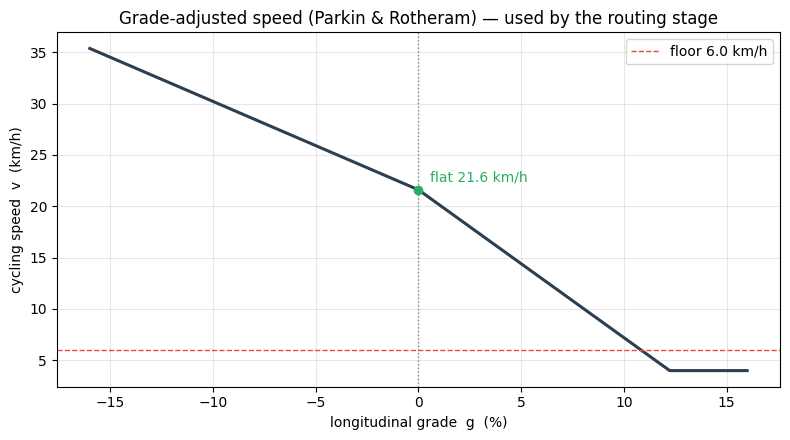

  Saved 01_speed_vs_grade.png


In [15]:
def grade_adjusted_speed(
    g_pct, vflat=21.6, kup=1.44, kdown=0.86, vmin=4.0
):
  # Piecewise linear speed formulation: applies kup reduction uphill and kdown gain downhill, floor at vmin
  return np.maximum(
      vmin, vflat - kup * np.maximum(g_pct, 0) + kdown * np.maximum(-g_pct, 0)
  )


# Determine maximum absolute gradient range for plotting (minimum range ±8%)
gmax = max(8.0, edges["grade_abs"].max() * 100 if "grade_abs" in edges else 8.0)
gg = np.linspace(-gmax, gmax, 400)
vv = grade_adjusted_speed(gg)

# Plot grade vs. speed curve
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(gg, vv, lw=2.2, color="#2c3e50")
ax.axhline(6.0, ls="--", color="#e74c3c", lw=1, label="floor 6.0 km/h")
ax.axvline(0, ls=":", color="#7f8c8d", lw=1)
ax.scatter([0], [21.6], zorder=5, color="#27ae60")
ax.annotate(
    "flat 21.6 km/h",
    (0, 21.6),
    textcoords="offset points",
    xytext=(8, 6),
    color="#27ae60",
)
ax.set_xlabel("longitudinal grade  g  (%)")
ax.set_ylabel("cycling speed  v  (km/h)")
ax.set_title(
    "Grade-adjusted speed (Parkin & Rotheram) — used by the routing stage"
)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()

# Save figure output to figures directory
plt.savefig(FIGURES / "01_speed_vs_grade.png", dpi=150, bbox_inches="tight")
plt.show()
print("  Saved 01_speed_vs_grade.png")

# B — Extract the Furth v2.2 input variables

One column per variable. Order matters: B.0 consolidates parallel paths first, then B.1→B.12 fill the
table, and B.13 confirms nothing is missing.


## B.0 Absorb parallel off-road paths into the road

OSM often maps a corridor as parallel geometries (carriageway + footway + cycleway). Off-road cycling edges
running alongside a road (within 10 m, ≥50% overlap, bearing within 30°) transfer their facility to the
road as `parallel_facility`; the absorbed edges and standalone sidewalks are dropped. Greenways with no
parallel road are kept.


In [16]:
print("[B.0] Consolidating parallel infrastructure...")
PARALLEL_BUFFER_M, MIN_OVERLAP_FRAC, MAX_ANGLE_DEG = 10, 0.50, 30
ROAD_HIGHWAYS = {"trunk","trunk_link","primary","primary_link","secondary","secondary_link",
    "tertiary","tertiary_link","residential","living_street","unclassified","service"}
OFFROAD_HIGHWAYS = {"footway","path","cycleway","pedestrian"}

def _bearing(geom):
    c = list(geom.coords)
    if len(c) < 2: return 0.0
    return math.degrees(math.atan2(c[-1][0]-c[0][0], c[-1][1]-c[0][1])) % 180

def _offroad_facility(row):
    hw, bic, des = safe_str(row.get("highway","")), safe_str(row.get("bicycle","")), safe_str(row.get("designation",""))
    if hw == "cycleway": return "track"
    if hw == "path":     return "none" if bic == "no" else "track"
    if des == "shared_path": return "track"
    if hw in {"footway","pedestrian"}: return "track" if bic in {"yes","designated"} else "none"
    return "none"

edges["_hw"]       = edges["highway"].apply(safe_str)
edges["_is_road"]  = edges["_hw"].isin(ROAD_HIGHWAYS)
edges["_is_off"]   = edges["_hw"].isin(OFFROAD_HIGHWAYS)
print(f"  Road edges: {edges['_is_road'].sum():,} | off-road: {edges['_is_off'].sum():,}")

ep = edges.to_crs(METRIC_CRS)
roads = ep[ep["_is_road"]].copy();  roads["_orig"] = roads.index.tolist(); roads = roads.reset_index(drop=True)
offs  = ep[ep["_is_off"]].copy();   offs["_orig"]  = offs.index.tolist();  offs  = offs.reset_index(drop=True)
offs["_provides"] = offs.apply(_offroad_facility, axis=1)
roads["_bearing"] = roads.geometry.apply(_bearing)
offs["_bearing"]  = offs.geometry.apply(_bearing)

roads_buf = roads[["geometry"]].copy(); roads_buf.geometry = roads_buf.geometry.buffer(PARALLEL_BUFFER_M)
matched = gpd.sjoin(roads_buf, offs[["geometry","_provides","_orig","_bearing"]],
                    how="inner", predicate="intersects")
matched["_rb"] = roads["_bearing"].reindex(matched.index).values
matched["_adiff"] = np.minimum(np.abs(matched["_rb"]-matched["_bearing"]),
                               180-np.abs(matched["_rb"]-matched["_bearing"]))
matched = matched[matched["_adiff"] <= MAX_ANGLE_DEG].copy()

buf_lk, off_lk = roads_buf.geometry.to_dict(), offs.geometry.to_dict()
def _ovl(row):
    try:
        off = off_lk[row["index_right"]]
        return 0.0 if off.length == 0 else off.intersection(buf_lk[row.name]).length/off.length
    except Exception: return 0.0
matched["_ovl"] = matched.apply(_ovl, axis=1)
matched = matched[matched["_ovl"] >= MIN_OVERLAP_FRAC].copy()

RANK = {"track":3,"lane":2,"mixed":1,"none":0}
off_orig_lk, road_orig_lk = offs["_orig"].to_dict(), roads["_orig"].to_dict()
absorbed, road_parallel = set(), {}
for ri, oi, prov in zip(matched.index, matched["index_right"], matched["_provides"]):
    absorbed.add(off_orig_lk[oi]); ro = road_orig_lk[ri]
    if RANK.get(prov,0) > RANK.get(road_parallel.get(ro,"none"),0):
        road_parallel[ro] = prov

edges["parallel_facility"] = ""
for oi, fac in road_parallel.items():
    if oi in edges.index: edges.loc[oi,"parallel_facility"] = fac
edges["_absorbed"] = edges.index.isin(absorbed)
standalone = (edges["_is_off"] & ~edges["_absorbed"] & edges["_hw"].isin({"footway","pedestrian"})
              & ~edges["bicycle"].apply(lambda b: safe_str(b) in {"yes","designated"}))
edges.loc[standalone, "_absorbed"] = True

n_before = len(edges)
edges = edges[~edges["_absorbed"]].copy()
for c in ["_hw","_is_road","_is_off","_absorbed"]:
    if c in edges.columns: edges.drop(columns=c, inplace=True)
print(f"  Roads with parallel cycling infra: {(edges['parallel_facility']!='').sum():,}")
print(f"  Edges {n_before:,} -> {len(edges):,} (absorbed {n_before-len(edges):,})")

[B.0] Consolidating parallel infrastructure...
  Road edges: 38,898 | off-road: 54,763
  Roads with parallel cycling infra: 3,160
  Edges 97,818 -> 50,560 (absorbed 47,258)


## B.1 Highway class

The OSM `highway` tag — the fundamental Furth branch selector.


In [17]:
print("[B.1] Highway class...")
edges["hw"] = edges.apply(lambda r: safe_str(r.get("highway","unclassified")) or "unclassified", axis=1)
print(edges["hw"].value_counts().head(12).to_string())

[B.1] Highway class...
hw
service          13661
residential      13286
cycleway          4030
tertiary          3569
steps             2939
secondary         2502
unclassified      2147
primary           2110
footway           1548
path              1430
corridor           701
living_street      658


## B.2 Prevailing speed (km/h) + source

Priority: **Compass GPS p85 → TfNSW signposted → OSM maxspeed → NSW statutory default** (built-up-area 50;
shared zone 10). `speed_source` records which source fired, so the report can quantify default reliance.


In [18]:
print("[B.2] Prevailing speed (km/h)...")

# NSW statutory default speeds by road context (last resort only).
NSW_STATUTORY_KMH = {
    "living_street":10,"residential":50,"service":50,"unclassified":50,
    "tertiary":50,"tertiary_link":50,"secondary":50,"secondary_link":50,
    "primary":50,"primary_link":50,"trunk":50,"trunk_link":50,
    "motorway":50,"motorway_link":50,
    "cycleway":0,"footway":0,"path":0,"pedestrian":10,
}

# Parse an OSM maxspeed tag to km/h (handling mph), or None if unusable.
def _parse_maxspeed(raw):
    if raw in ("","nan","none"): return None
    try:
        if "mph" in raw: return round(float(raw.replace("mph","").strip())*MPH_TO_KMH, 1)
        return round(float(raw.replace("km/h","").replace("kph","").strip()), 1)
    except ValueError: return None

# Speed hierarchy: Compass GPS p85 -> TfNSW signposted -> OSM maxspeed -> NSW statutory default.
def get_speed_kmh(r):
    gps = r.get("gps_speed_kmh", np.nan)
    if pd.notna(gps) and gps > 0: return round(float(gps),1)
    tf = r.get("tfnsw_speed_kmh", np.nan)
    if pd.notna(tf) and tf > 0: return round(float(tf),1)
    ms = _parse_maxspeed(safe_str(r.get("maxspeed","")))
    if ms is not None and ms > 0: return ms
    return float(NSW_STATUTORY_KMH.get(r["hw"], 50))

# Record which source actually supplied each edge's speed.
def get_speed_source(r):
    if pd.notna(r.get("gps_speed_kmh",np.nan)) and r.get("gps_speed_kmh",0) > 0: return "gps_p85"
    if pd.notna(r.get("tfnsw_speed_kmh",np.nan)) and r.get("tfnsw_speed_kmh",0) > 0: return "tfnsw_signposted"
    if _parse_maxspeed(safe_str(r.get("maxspeed",""))) is not None: return "osm_maxspeed"
    return "nsw_statutory_default"

edges["speed_kmh"]    = edges.apply(get_speed_kmh, axis=1)
edges["speed_source"] = edges.apply(get_speed_source, axis=1)
edges["speed_band"]   = edges["speed_kmh"].apply(speed_band)   # coarse, reporting-only

print("  Source breakdown (priority GPS>TfNSW>OSM>default):")
for src, n in edges["speed_source"].value_counts().items():
    print(f"    {src:<22}{n:>6}  ({100*n/len(edges):5.1f}%)")
nd = (edges["speed_source"]=="nsw_statutory_default").sum()
print(f"  Last-resort default reliance: {nd:,} ({100*nd/len(edges):.1f}%)")
print(f"  -> quote GPS p85 coverage = {100*(edges['speed_source']=='gps_p85').mean():.1f}% of edges in the thesis")


[B.2] Prevailing speed (km/h)...
  Source breakdown (priority GPS>TfNSW>OSM>default):
    gps_p85                31565  ( 62.4%)
    tfnsw_signposted       13355  ( 26.4%)
    nsw_statutory_default   5227  ( 10.3%)
    osm_maxspeed             413  (  0.8%)
  Last-resort default reliance: 5,227 (10.3%)
  -> quote GPS p85 coverage = 62.4% of edges in the thesis


## B.3–B.7 Lane and directional attributes

Derives total lanes (tag or class default), one-way status honouring `oneway:bicycle=no` contraflow,
lanes per direction, an inferred centreline, and the Furth mixed-traffic `lane_category`.


In [19]:
# [B.3] Extract or infer total lane counts for the road segment
print("[B.3] Total lanes...")
def get_total_lanes(r):
    raw = safe_str(r.get("lanes",""))
    # If a valid OSM lane tag exists, parse it to an integer
    if raw not in ("","nan","none"):
        try: return int(float(raw))
        except ValueError: pass
    # If the tag is missing, apply assumption-based defaults using the highway (hw) classification
    return {"living_street":2,"residential":2,"service":1,"unclassified":2,
            "tertiary":2,"tertiary_link":1,"secondary":3,"secondary_link":1,
            "primary":4,"primary_link":1,"trunk":3,"trunk_link":2,"motorway":6,"motorway_link":2,
            "cycleway":0,"footway":0,"path":0,"pedestrian":0,"corridor":0,"steps":0}.get(r["hw"], 2)
# Apply function and track whether the lane count came from an explicit tag or our default dictionary
edges["lanes_total"]  = edges.apply(get_total_lanes, axis=1)
edges["lanes_source"] = edges.apply(
    lambda r: "osm_tag" if safe_str(r.get("lanes","")) not in ("","nan","none") else "default", axis=1)
print(f"  From OSM tag: {(edges['lanes_source']=='osm_tag').sum():,}")

# [B.4] Determine routing directionality and contraflow exceptions
print("[B.4] One-way status (honours oneway:bicycle=no contraflow)...")
# Check if road is one-way for general motor traffic
def _ow_motor(r): return safe_str(r.get("oneway","")) in {"yes","true","1","-1"}
# Check if bicycles are explicitly permitted to travel against motor traffic (contraflow)
def _contra(r):   return _ow_motor(r) and safe_str(r.get("oneway:bicycle","")) in {"no","false","0"}
edges["is_oneway_motor"] = edges.apply(_ow_motor, axis=1)
edges["bike_contraflow"] = edges.apply(_contra, axis=1)
# Bicycles are only subject to one-way routing if it's one-way for motors AND no contraflow exists
edges["is_oneway"]       = edges["is_oneway_motor"] & (~edges["bike_contraflow"])
print(f"  One-way (motor): {edges['is_oneway_motor'].sum():,} | "
      f"contraflow: {edges['bike_contraflow'].sum():,} | one-way for bikes: {edges['is_oneway'].sum():,}")

# [B.5] Calculate the number of lanes in the direction of travel (required for LTS matrices)
print("[B.5] Lanes per direction...")
NON_ROAD_HW = {"cycleway","footway","path","pedestrian","steps","corridor"}
def _dir_tag(r):
    # Determine the direction of the digitised edge to pull the correct forward/backward lane tag
    rev = r.get("reversed", False)
    if isinstance(rev, str): rev = rev.lower()=="true"
    if isinstance(rev, (list,tuple)): rev = bool(rev[0]) if rev else False
    raw = safe_str(r.get("lanes:backward" if rev else "lanes:forward",""))
    if raw not in ("","nan","none"):
        try: return max(1, int(float(raw)))
        except ValueError: return None
    return None
def _lpd(r):
    # Off-road paths have 0 lanes
    if r["hw"] in NON_ROAD_HW: return 0
    # Use explicit directional lane tags if they exist
    t = _dir_tag(r)
    if t is not None: return t
    lt = int(r["lanes_total"])
    # If untagged, assume all lanes are one direction (if one-way), or half the lanes per direction (if two-way)
    return max(1, lt) if r["is_oneway"] else max(1, lt//2)
edges["lanes_per_dir"] = edges.apply(_lpd, axis=1)
print(edges["lanes_per_dir"].value_counts().sort_index().to_string())

# [B.6] Infer the presence of a centreline (required for Furth LTS mixed-traffic calculation)
print("[B.6] Centreline (inferred)...")
NEVER = NON_ROAD_HW
HIGHER = {"tertiary","tertiary_link","secondary","secondary_link",
          "primary","primary_link","trunk","trunk_link","motorway","motorway_link"}
def _centre(r):
    hw = r.get("hw","")
    if hw in NEVER:  return False
    # Assume centrelines exist on higher order arterial/collector roads
    if hw in HIGHER: return True
    # Centrelines do not exist on one-way streets
    if bool(r.get("is_oneway", False)): return False
    tagged = r.get("lanes_source","")=="osm_tag"
    try: two_plus = float(r.get("lanes_total",1)) >= 2
    except (TypeError,ValueError): two_plus = False
    # For lower-order roads, only assume a centreline if explicitly tagged with 2+ lanes
    return bool(tagged and two_plus)
edges["has_centreline"] = edges.apply(_centre, axis=1)
print(f"  With centreline: {edges['has_centreline'].sum():,}")

# [B.7] Map derived attributes to Furth LTS v2.2 table row selectors
print("[B.7] Lane category (Furth mixed-traffic row selector)...")
def get_lane_category(r):
    hw, centre, ow, lpd = r["hw"], r["has_centreline"], r["is_oneway"], r["lanes_per_dir"]
    # Maps directly to the decision variables in Furth v2.2 mixed-traffic matrices
    if hw in NON_ROAD_HW: return "non_road"
    if lpd >= 3: return "3plus_per_dir"
    if lpd == 2: return "2_lanes_per_dir"
    if ow:
        return "narrow_1way" if hw in {"residential","living_street","service"} else "wide_1way_or_centre"
    return "wide_1way_or_centre" if centre else "unlaned_2way"
edges["lane_category"] = edges.apply(get_lane_category, axis=1)
print(edges["lane_category"].value_counts().to_string())

[B.3] Total lanes...
  From OSM tag: 13,957
[B.4] One-way status (honours oneway:bicycle=no contraflow)...
  One-way (motor): 7,859 | contraflow: 457 | one-way for bikes: 7,402
[B.5] Lanes per direction...
lanes_per_dir
0    11145
1    32369
2     4987
3     1456
4      546
5       40
6       17
[B.6] Centreline (inferred)...
  With centreline: 12,985
[B.7] Lane category (Furth mixed-traffic row selector)...
lane_category
unlaned_2way           22614
non_road               11145
wide_1way_or_centre     7691
2_lanes_per_dir         4987
narrow_1way             2064
3plus_per_dir           2059


## B.8 Facility type

Maps each edge to a Furth facility category — `track` (physically separated), `lane_no_park`,
`lane_with_park` (door-zone), `mixed`, or `excluded` (motorways, prohibited tunnels, non-cyclable paths).
The final run uses `FACILITY_LINK_RULE = direction_specific`: each edge keeps its own side's facility
(the worst-side rule is instead applied to **LTS** in Notebook 02).


In [20]:
print("[B8] Facility type (direction-aware)...")
def get_facility_type(r):
    # Safely extract basic highway, bicycle, and designation tags
    hw, bic, des = safe_str(r.get("highway","")), safe_str(r.get("bicycle","")), safe_str(r.get("designation",""))
    
    # Handle directional differences in cycleway tags (e.g., cycleway:right vs cycleway:left)
    rev = r.get("reversed", False)
    if isinstance(rev, str): rev = rev.lower()=="true"
    cy, cy_b = safe_str(r.get("cycleway","")), safe_str(r.get("cycleway:both",""))
    if rev:
        cy_mine, cy_other = safe_str(r.get("cycleway:right","")), safe_str(r.get("cycleway:left",""))
    else:
        cy_mine, cy_other = safe_str(r.get("cycleway:left","")),  safe_str(r.get("cycleway:right",""))
    my_cy  = {cy, cy_b, cy_mine}
    all_cy = {cy, cy_b, cy_mine, cy_other}

    # 1. Base Exclusions: Remove motorways, stairs, and indoor corridors
    if hw == "motorway" or hw in {"steps","corridor"}: return "excluded"
    
    # 2. Pedestrian Path Exclusions: Exclude footways and pedestrian zones unless cycling is explicitly designated/permitted
    if hw == "footway":    return "track" if bic in {"yes","designated"} else "excluded"
    if hw == "pedestrian": return "track" if bic in {"yes","designated"} else "excluded"

    # 3. Major Tunnel Exclusions: Explicitly exclude major subterranean motorways that prohibit bicycles
    name, tunnel = safe_str(r.get("name","")), safe_str(r.get("tunnel",""))
    PROHIBITED = {"sydney harbour tunnel","cross city tunnel","lane cove tunnel",
                  "eastern distributor","m5 east tunnel","westconnex m8","westconnex m4 tunnel"}
    if tunnel == "yes" and (name in PROHIBITED or hw in {"motorway","motorway_link"}):
        return "excluded"

    # 4. Off-Road and Separated Infrastructure ("track")
    if hw == "cycleway": return "mixed" if cy == "crossing" else "track"
    if hw == "path":     return "excluded" if bic == "no" else "track"
    if des == "shared_path": return "track"
    if any(c in {"track","sidepath","separate"} for c in all_cy): return "track"
    # Inherit "track" status if this road absorbed a parallel cycleway in Cell B0
    if safe_str(r.get("parallel_facility","")) == "track": return "track"
    
    # 5. Shared Motor-Vehicle Space
    if any(c in {"shared_lane","share_busway"} for c in my_cy): return "mixed"

    # 6. Painted Bike Lanes (Split by Parking Conflict)
    if any(c == "lane" for c in my_cy):
        # Extract all possible OSM parking tags to determine if the bike lane is in the door zone
        allp = [safe_str(r.get(t,"")) for t in
                ("parking:both","parking:left","parking:right",
                 "parking:lane:left","parking:lane:right","parking:lane:both","parking:both:restriction")]
        YES = {"parallel","diagonal","perpendicular","yes","marked","lane","street_side","ticket","metered"}
        NO  = {"no","no_stopping","no_parking","no_standing","fire_lane","separate","bus_zone","clearway"}
        
        # Explicit parking prohibitions mean the lane is conflict-free (lane_no_park)
        if any(t in NO  for t in allp): return "lane_no_park"
        # Explicit parking permitted means the lane is in the door zone (lane_with_park)
        if any(t in YES for t in allp): return "lane_with_park"
        
        # Default fallback: Assume higher-order roads and local residential streets allow curbside parking
        if hw in {"primary","primary_link","secondary","secondary_link",
                  "tertiary","tertiary_link","residential","living_street"}: return "lane_with_park"
        return "lane_no_park"
        
    # Advisory lanes and shoulders are treated as unprotected lanes without parking conflict
    if cy in {"advisory","shoulder"}: return "lane_no_park"
    
    # Everything else defaults to mixed traffic
    return "mixed"

edges["facility_type"] = edges.apply(get_facility_type, axis=1)
print(edges["facility_type"].value_counts().to_string())

# [Link-Level Aggregation] Resolve asymmetric cycle facilities on two-way roads
# The routing engine treats undirected edges symmetrically. If a road has a track on one side 
# and mixed traffic on the other, Furth requires the entire link to adopt the worst facility.
if "link_id" in edges.columns and "parallel_facility" in edges.columns:
    has = edges.groupby("link_id")["parallel_facility"].transform(lambda s: (s=="track").any())
    edges.loc[has, "parallel_facility"] = "track"
    edges.loc[has & (edges["facility_type"]!="excluded"), "facility_type"] = "track"
    
    # FACILITY_LINK_RULE determines how to resolve conflict. "worst" takes the highest stress facility.
    if FACILITY_LINK_RULE == "worst":
        STRESS = {"track":0,"lane_no_park":1,"lane_with_park":2,"mixed":3,"excluded":4}
        inv = {v:k for k,v in STRESS.items()}
        worst = edges.groupby("link_id")["facility_type"].transform(lambda s: s.map(STRESS).max())
        keep = edges["facility_type"]=="track"
        edges.loc[~keep,"facility_type"] = worst[~keep].map(inv)
        print("  Applied 'worst' link rule.")
    else:
        print("  FACILITY_LINK_RULE='direction_specific' — left each edge as-is.")
asym = (edges.groupby("link_id")["facility_type"].nunique() > 1).sum()
print(f"  Direction-asymmetric links: {asym:,}")

[B8] Facility type (direction-aware)...
facility_type
mixed             35911
track              9770
excluded           4051
lane_with_park      772
lane_no_park         56
  FACILITY_LINK_RULE='direction_specific' — left each edge as-is.
  Direction-asymmetric links: 210


## B.9–B.12 Geometry, parking, reach, and ADT

Bike-lane width (tag or default, in feet), parking presence (3-value, with a Street-View validation
sample), door-zone reach, and motor ADT by a measured-first hierarchy (on-link count → nearby same-class
count → class average → Harvey scaled fallback).


In [21]:
# ============================================================
# B.9 — BIKE LANE WIDTH
# ============================================================
print("[B.9] Bike lane width...")

def _bw(r):
    # Only assign lane width if the facility is a painted bike lane (with or without parking)
    if r.get("facility_type") not in {"lane_no_park", "lane_with_park"}:
        return np.nan

    # Check various OSM width tag variations for left/right lanes
    for tag in [
        "cycleway:width",
        "cycleway:left:width",
        "cycleway:right:width",
    ]:
        raw = str(r.get(tag, "")).strip().lower()

        if raw not in ("", "nan", "none"):
            try:
                # Handle list-formatted strings if present in OSM tags
                if "[" in raw:
                    raw = (
                        raw.replace("[", "")
                           .replace("]", "")
                           .split(",")[0]
                           .strip()
                    )

                # Convert meters to feet (Furth LTS formulas natively use feet)
                return float(raw.replace("m", "").strip()) * 3.28084

            except (ValueError, TypeError):
                pass

    # Fallback to standard default bike lane width if no explicit tag exists
    return DEFAULT_BIKE_LANE_WIDTH_FT


edges["bike_lane_width_ft"] = edges.apply(_bw, axis=1)

print(
    f"  Lane widths assigned: "
    f"{edges['bike_lane_width_ft'].notna().sum():,}"
)


# ============================================================
# B.10 — PARKING PRESENCE AND SOURCE TRACKING
# ============================================================
print("[B.10] Parking presence (yes/no/unknown) + source...")

# Definitive OSM tags indicating permitted curbside parking
YES = {
    "parallel", "diagonal", "perpendicular", "yes", "marked",
    "lane", "street_side", "ticket", "metered",
}

# Definitive OSM tags indicating prohibited curbside parking
NO = {
    "no", "no_parking", "no_stopping", "no_standing",
    "separate", "bus_zone", "clearway", "fire_lane",
}

PARKING_TAGS = (
    "parking:both",
    "parking:left",
    "parking:right",
    "parking:lane:left",
    "parking:lane:right",
    "parking:lane:both",
)


def _parking_tags_raw(r):
    """Return non-empty OSM parking tag values."""
    parts = []

    for tag in PARKING_TAGS:
        value = safe_str(r.get(tag, ""))

        if value not in ("", "nan", "none"):
            parts.append(f"{tag}={value}")

    return "; ".join(parts)


def get_parking(r):
    tags = [safe_str(r.get(tag, "")) for tag in PARKING_TAGS]

    # If any explicit parking tag indicates parking is allowed, set to 'yes'
    if any(tag in YES for tag in tags):
        return "yes"

    # If any explicit parking tag indicates parking is prohibited, set to 'no'
    if any(tag in NO for tag in tags):
        return "no"

    # Fall back to highway-class default dictionary if untagged
    return PARKING_CLASS_DEFAULT.get(r.get("hw", ""), "unknown")


def get_parking_source(r):
    """Identify whether parking came from an OSM tag or class default."""
    for tag in PARKING_TAGS:
        value = safe_str(r.get(tag, ""))

        if value not in ("", "nan", "none"):
            return "osm_tag"

    return "class_default"


edges["parking"] = edges.apply(get_parking, axis=1)
edges["parking_source"] = edges.apply(get_parking_source, axis=1)
edges["osm_parking_tags"] = edges.apply(_parking_tags_raw, axis=1)

print(edges["parking"].value_counts().to_string())
print("  by source:")
print(edges["parking_source"].value_counts().to_string())
print(f"  (unknown -> '{PARKING_UNKNOWN_AS}' downstream for LTS)")


# ============================================================
# B.10.1 — PARKING DEFAULT VALIDATION SAMPLE
# ============================================================

# Define helper functions to generate Google Street View verification links for auditing defaults
def _mid(geom):
    """Return midpoint latitude and longitude."""
    p = geom.interpolate(0.5, normalized=True)
    return p.y, p.x


def _hdg(geom):
    """Return approximate compass heading in degrees."""
    p1 = geom.interpolate(0.45, normalized=True)
    p2 = geom.interpolate(0.55, normalized=True)

    return (
        math.degrees(
            math.atan2(p2.x - p1.x, p2.y - p1.y)
        ) + 360
    ) % 360


def _sv(lat, lon, heading):
    """Build a Google Maps Street View URL."""
    return (
        "https://www.google.com/maps/@?api=1&map_action=pano"
        f"&viewpoint={lat},{lon}&heading={heading:.1f}"
    )


PARKING_SAMPLE_PER_CLASS = 10


def export_parking_default_sampling(
    df,
    n_per=PARKING_SAMPLE_PER_CLASS,
    seed=VALIDATION_SEED,
    out_path=REPORTS / "parking_default_sampling.csv",
):
    print(
        f"[VAL-P] Parking default sampling "
        f"(seed={seed}, n_per={n_per})..."
    )

    required = {"parking_source", "hw", "geometry"}
    missing = required.difference(df.columns)

    if missing:
        print(f"  Missing required columns: {sorted(missing)}")
        return None

    # Filter for rows where class defaults were applied
    defaulted = df[df["parking_source"] == "class_default"].copy()

    if defaulted.empty:
        print("  No defaulted rows — skipping")
        return None

    tagged = df[df["parking_source"] == "osm_tag"].copy()

    parts = []

    # Sample defaulted rows per highway class for manual review
    for hw, sub in defaulted.groupby("hw", dropna=False):
        if not sub.empty:
            parts.append(
                sub.sample(
                    n=min(n_per, len(sub)),
                    random_state=seed,
                )
            )

    # Sample OSM-tagged rows for quality cross-checks
    for hw, sub in tagged.groupby("hw", dropna=False):
        if not sub.empty:
            parts.append(
                sub.sample(
                    n=min(3, len(sub)),
                    random_state=seed,
                )
            )

    if not parts:
        print("  No parking samples available — skipping")
        return None

    out = pd.concat(parts).copy()

    if isinstance(out.index, pd.MultiIndex):
        if {"u", "v", "key"}.issubset(out.index.names):
            out = out.reset_index()

    coords = out.geometry.apply(_mid)

    out["lat"] = coords.apply(lambda c: c[0])
    out["lon"] = coords.apply(lambda c: c[1])
    out["heading"] = out.geometry.apply(_hdg)

    out["streetview_url"] = out.apply(
        lambda r: _sv(r["lat"], r["lon"], r["heading"]),
        axis=1,
    )

    out["current_default_used"] = out.apply(
        lambda r: (
            PARKING_CLASS_DEFAULT.get(r["hw"], "unknown")
            if r["parking_source"] == "class_default"
            else ""
        ),
        axis=1,
    )

    out["osm_parking_tags"] = out.apply(
        lambda r: (
            r.get("osm_parking_tags", "")
            if r["parking_source"] == "osm_tag"
            else ""
        ),
        axis=1,
    )

    out["observed_parking"] = ""
    out["notes"] = ""

    keep = [
        "hw",
        "u",
        "v",
        "key",
        "name",
        "osm_parking_tags",
        "current_default_used",
        "parking_source",
        "streetview_url",
        "observed_parking",
        "notes",
    ]

    keep = [col for col in keep if col in out.columns]
    out = out[keep].rename(columns={"hw": "highway"})

    for col in out.columns:
        if out[col].dtype == object:
            out[col] = out[col].apply(
                lambda x: str(x[0]) if isinstance(x, list) else x
            )

    out_path = Path(out_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)

    out.to_csv(out_path, index=False)

    print(
        f"  Wrote {len(out)} rows across "
        f"{out['highway'].nunique()} classes -> {out_path.name}"
    )
    print("  Per-class counts:")
    print(
        out.groupby(["highway", "parking_source"], dropna=False)
           .size()
           .to_string()
    )

    return out


export_parking_default_sampling(edges)

# ============================================================
# B.11 — BIKE LANE REACH
# ============================================================
print("[B.11] Bike lane reach...")


def _reach(r):
    fac = r.get("facility_type")
    park = r.get("parking")

    park_eff = PARKING_UNKNOWN_AS if park == "unknown" else park

    # Apply reach calculations only to lanes with parking conflict
    if fac == "lane_with_park":
        pass
    elif fac == "lane_no_park" and park_eff == "yes":
        pass
    else:
        return np.nan

    bw = r.get("bike_lane_width_ft")

    if pd.isna(bw):
        bw = DEFAULT_BIKE_LANE_WIDTH_FT

    # Total reach = bike lane width + parking stall width (crucial for Furth LTS door-zone evaluation)
    return bw + PARKING_STALL_FT


edges["bike_lane_reach_ft"] = edges.apply(_reach, axis=1)

print(
    f"  Reach assigned: "
    f"{edges['bike_lane_reach_ft'].notna().sum():,}"
)


# ============================================================
# B.12 — ADT PER LINK (MEASURED-FIRST)
# ============================================================
print("[B.12] ADT per link (measured-first)...")

MOTOR_FAC = {"mixed", "lane_no_park", "lane_with_park"}

needs = (
    edges["hw"].isin(DRIVABLE_CLASSES)
    | edges["facility_type"].isin(MOTOR_FAC)
)

print(f"  Edges needing ADT: {int(needs.sum()):,}")

_adt = {}
_src = {}

em = edges.to_crs(METRIC_CRS).reset_index(drop=True).copy()
em["eid"] = np.arange(len(em))
em["need"] = needs.to_numpy()

elig = em[em["need"]].copy()

have = (
    stations_m is not None
    and not stations_m.empty
)

st = None

if have:
    required_station_cols = {
        "station_id", "aadt_ref", "hw", "geometry"
    }
    missing_station_cols = required_station_cols.difference(
        stations_m.columns
    )

    if missing_station_cols:
        print(
            "  WARNING: stations_m is missing columns "
            f"{sorted(missing_station_cols)}; using fallback ADT values."
        )
        have = False
    else:
        st = stations_m[
            ["station_id", "aadt_ref", "hw", "geometry"]
        ].copy()

if have and not elig.empty:

    # --------------------------------------------------------
    # 1. Closest measured count on the same link
    # --------------------------------------------------------
    on = gpd.sjoin_nearest(
        elig[["eid", "link_id", "geometry"]],
        st[["station_id", "aadt_ref", "geometry"]],
        how="inner",
        max_distance=ADT_ON_LINK_M,
        distance_col="d",
    )

    on = (
        on.sort_values("d")
          .drop_duplicates("eid", keep="first")
    )

    for r in on.itertuples(index=False):
        _adt[r.eid] = float(r.aadt_ref)
        _src[r.eid] = "on_link"

    link_val = {}

    for r in on.itertuples(index=False):
        link_val.setdefault(r.link_id, r.aadt_ref)

    for r in elig.itertuples(index=False):
        if r.eid not in _adt and r.link_id in link_val:
            _adt[r.eid] = float(link_val[r.link_id])
            _src[r.eid] = "on_link"

    # --------------------------------------------------------
    # 2. Nearby measured count of the same highway class
    # --------------------------------------------------------
    rem = elig[~elig["eid"].isin(_adt)].copy()

    for hw_cls, grp in rem.groupby("hw", dropna=False):

        sc = st[st["hw"] == hw_cls]

        if sc.empty:
            continue

        nr = gpd.sjoin_nearest(
            grp[["eid", "geometry"]],
            sc[["aadt_ref", "geometry"]],
            how="inner",
            max_distance=ADT_SAME_TYPE_M,
            distance_col="d",
        )

        nr = (
            nr.sort_values("d")
              .drop_duplicates("eid", keep="first")
        )

        for r in nr.itertuples(index=False):
            _adt[r.eid] = float(r.aadt_ref)
            _src[r.eid] = "nearby_same_type"


# ------------------------------------------------------------
# 3. Fallbacks for edges without a measured value
# ------------------------------------------------------------
for r in em.itertuples(index=False):

    eid = r.eid
    hw = r.hw
    need_adt = r.need

    if not need_adt:
        _adt[eid] = 0.0
        _src.setdefault(eid, "no_motor_traffic")
        continue

    if eid in _adt:
        continue

    # Use class averages or Harvey regional defaults if no local count is matched
    if hw in class_avg:
        _adt[eid] = float(class_avg[hw])
        _src[eid] = "class_average"
    else:
        _adt[eid] = float(harvey_def.get(hw, 0))
        _src[eid] = "harvey_scaled"

# ------------------------------------------------------------
# 4. Assign ADT back to edges by row position
# ------------------------------------------------------------
edges["adt"] = [
    _adt.get(eid, 0.0)
    for eid in range(len(edges))
]

edges["adt_source"] = [
    _src.get(eid, "no_motor_traffic")
    for eid in range(len(edges))
]

print("  ADT source breakdown:")

for source, count in edges["adt_source"].value_counts().items():
    print(f"    {source:<20}{count:>7,}")

meas = edges["adt_source"].isin(
    {"on_link", "nearby_same_type"}
)

print(
    f"  MEASURED on {int(meas.sum()):,} of "
    f"{int(needs.sum()):,} motor edges "
    f"({100 * meas.sum() / max(int(needs.sum()), 1):.1f}%)"
)

[B.9] Bike lane width...
  Lane widths assigned: 828
[B.10] Parking presence (yes/no/unknown) + source...
parking
yes        31406
no         15281
unknown     3873
  by source:
parking_source
class_default    48781
osm_tag           1779
  (unknown -> 'yes' downstream for LTS)
[VAL-P] Parking default sampling (seed=42, n_per=10)...
  Wrote 284 rows across 25 classes -> parking_default_sampling.csv
  Per-class counts:
highway         parking_source
bridleway       class_default     10
busway          class_default     10
corridor        class_default     10
cycleway        class_default     10
                osm_tag            3
elevator        class_default     10
footway         class_default     10
living_street   class_default     10
                osm_tag            3
motorway        class_default     10
motorway_link   class_default     10
path            class_default     10
pedestrian      class_default     10
                osm_tag            2
primary         class_default

## B.13 Furth input checklist

Asserts all 11 required Furth variables exist before hand-off, halting if any is missing.


In [22]:
# Print header banner for the verification checklist
print("="*56 + "\nFURTH v2.2 INPUT CHECKLIST\n" + "="*56)

# Define the complete list of required attribute labels and their corresponding DataFrame column names
need = [("speed","speed_kmh"),("lanes/dir","lanes_per_dir"),("oneway","is_oneway"),
        ("centreline","has_centreline"),("lane_category","lane_category"),
        ("facility","facility_type"),("lane width","bike_lane_width_ft"),
        ("parking","parking"),("reach","bike_lane_reach_ft"),("ADT","adt"),("grade","grade_abs")]

allok = True

# Loop through each required column and check if it is present in the edges GeoDataFrame
for lab,c in need:
    ok = c in edges.columns; allok &= ok
    print(f"  {lab:<14}{c:<20}{'PRESENT' if ok else 'MISSING'}")

print("="*56)

# Halt execution immediately if any required variable is missing, preventing downstream classification errors
assert allok, "A Furth input is missing — do not proceed to NB02."

FURTH v2.2 INPUT CHECKLIST
  speed         speed_kmh           PRESENT
  lanes/dir     lanes_per_dir       PRESENT
  oneway        is_oneway           PRESENT
  centreline    has_centreline      PRESENT
  lane_category lane_category       PRESENT
  facility      facility_type       PRESENT
  lane width    bike_lane_width_ft  PRESENT
  parking       parking             PRESENT
  reach         bike_lane_reach_ft  PRESENT
  ADT           adt                 PRESENT
  grade         grade_abs           PRESENT


# C — Diagnostic panel

A 2×3 panel mapping highway class, prevailing speed, speed source, facility type, parking, and absolute
gradient across the study area.


[C] Diagnostic panel...


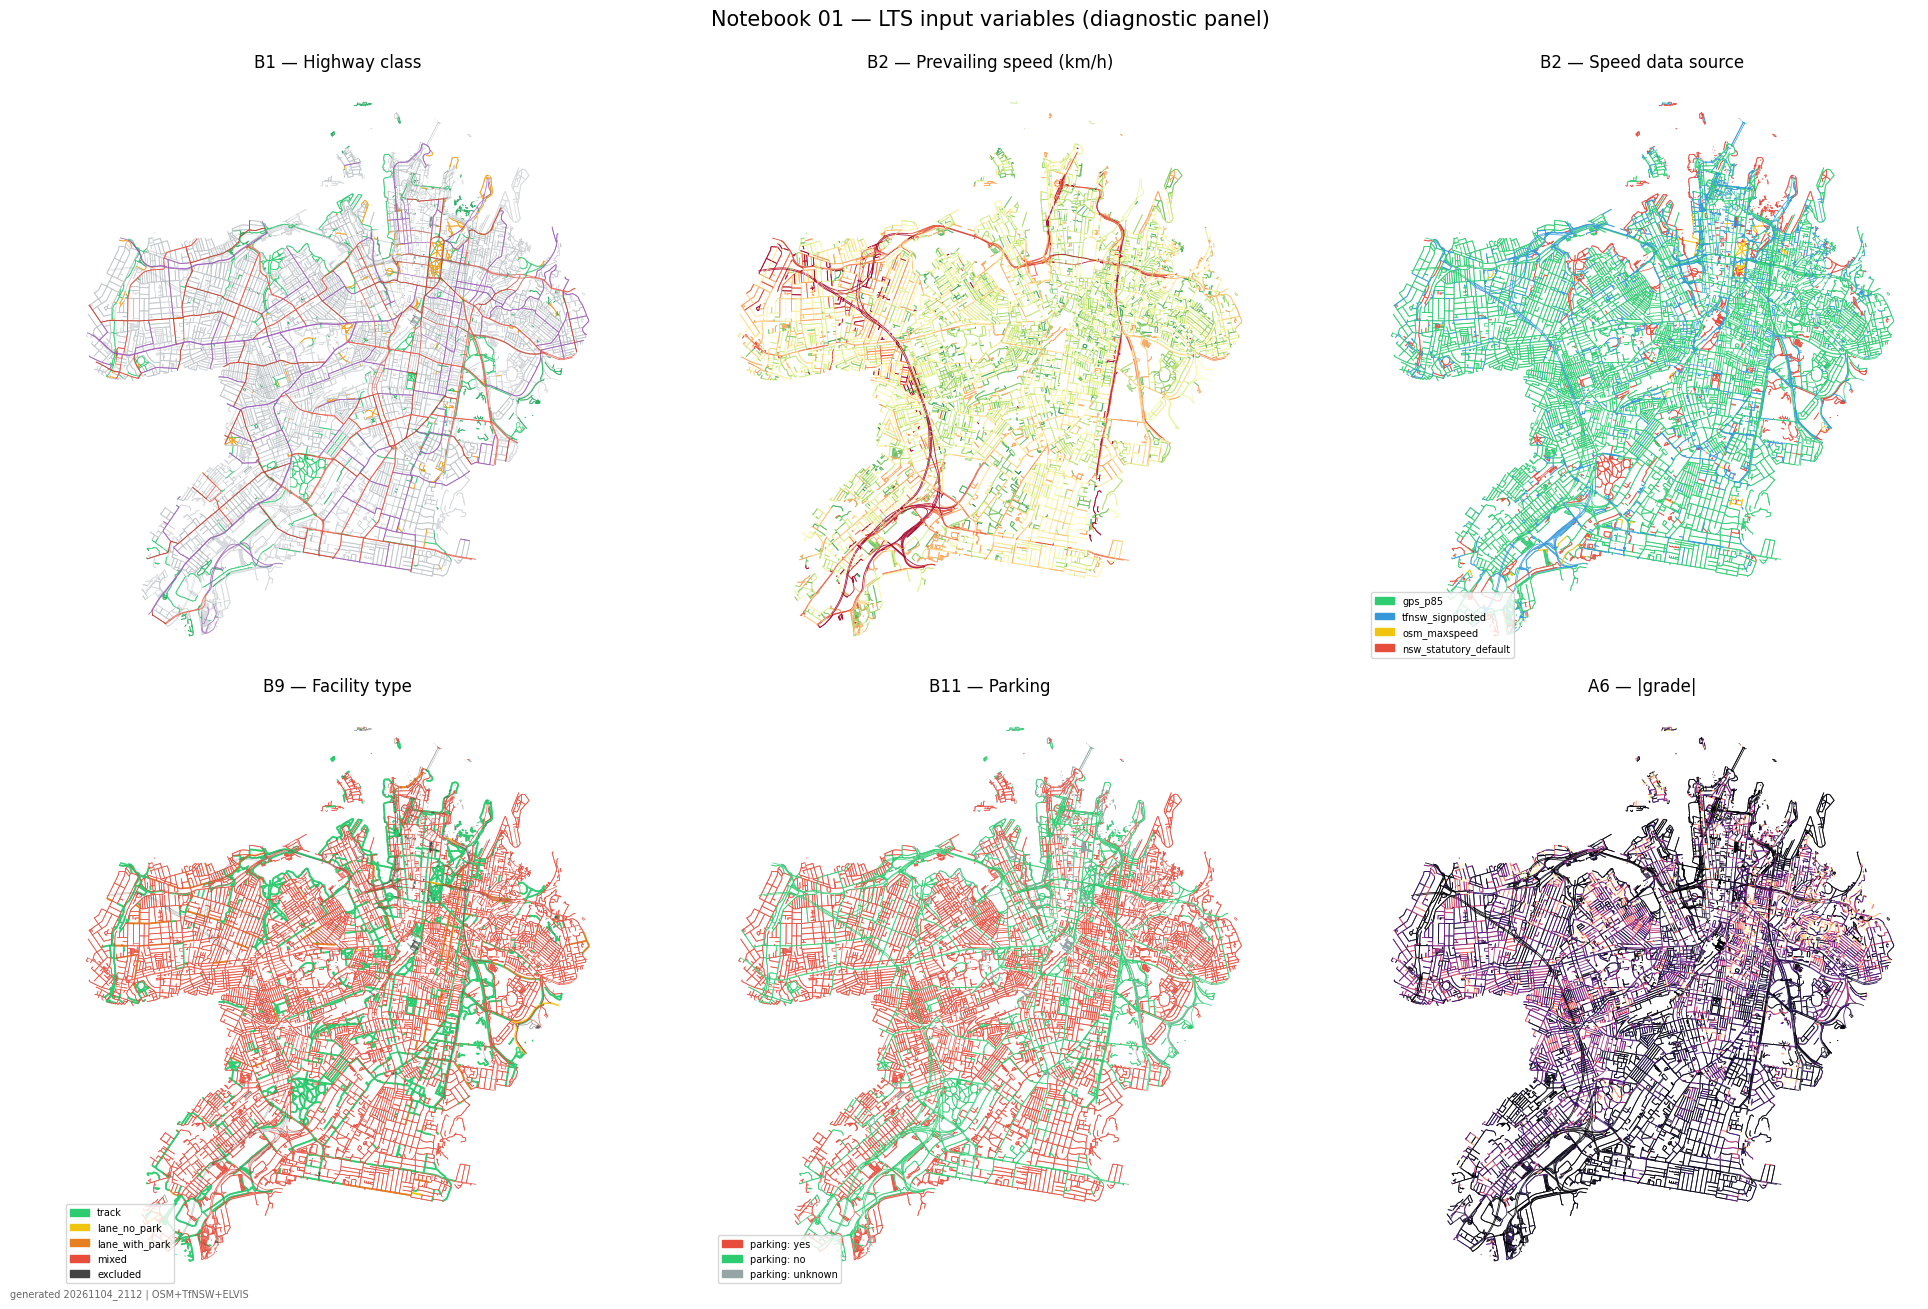

  Saved 01_variable_panel.png


In [23]:
print("[C] Diagnostic panel...")
NON_ROAD = {"cycleway","footway","path","pedestrian","steps","corridor"}
# Exclude non-road paths for general vehicular/speed mapping
road = edges[~edges["hw"].isin(NON_ROAD)]

# Initialise a 2x3 subplot grid for the six diagnostic maps
fig, axes = plt.subplots(2, 3, figsize=(20, 13))
for a in axes.ravel(): a.set_axis_off(); a.set_facecolor("white")

# Subplot 1: Highway classification color-coded by road type
hw_cols = {"cycleway":"#2ecc71","path":"#27ae60","footway":"#f39c12","residential":"#bdc3c7",
           "service":"#d5d8dc","tertiary":"#9b59b6","secondary":"#c0392b","primary":"#e74c3c","trunk":"#8e44ad"}
for hw,c in hw_cols.items():
    mk = edges["hw"]==hw
    if mk.any(): edges[mk].plot(ax=axes[0,0], color=c, linewidth=0.6, alpha=0.8)
edges[~edges["hw"].isin(hw_cols)].plot(ax=axes[0,0], color="#7f8c8d", linewidth=0.3, alpha=0.4)
axes[0,0].set_title("B1 — Highway class")

# Subplot 2: Prevailing operating speeds (km/h) using a diverging red-yellow-green colormap
norm = Normalize(vmin=0, vmax=70)
road.plot(ax=axes[0,1], column="speed_kmh", cmap="RdYlGn_r", norm=norm, linewidth=0.6, alpha=0.9)
axes[0,1].set_title("B2 — Prevailing speed (km/h)")

# Subplot 3: Data source hierarchy for operating speeds (GPS vs TfNSW vs OSM)
src_cols = {"gps_p85":"#2ecc71","tfnsw_signposted":"#3498db","osm_maxspeed":"#f1c40f","nsw_statutory_default":"#e74c3c"}
for s,c in src_cols.items():
    mk = edges["speed_source"]==s
    if mk.any(): edges[mk].plot(ax=axes[0,2], color=c, linewidth=0.6, alpha=0.85)
axes[0,2].legend(handles=[mpatches.Patch(color=c,label=s) for s,c in src_cols.items()
                          if (edges["speed_source"]==s).any()], loc="lower left", fontsize=7)
axes[0,2].set_title("B2 — Speed data source")

# Subplot 4: Classified cycling facility types (tracks, lanes, mixed, excluded)
fac_cols = {"track":"#2ecc71","lane_no_park":"#f1c40f","lane_with_park":"#e67e22","mixed":"#e74c3c","excluded":"#444444"}
for f,c in fac_cols.items():
    mk = edges["facility_type"]==f
    if mk.any():
        edges[mk].plot(ax=axes[1,0], color=c, alpha=0.3 if f=="excluded" else 0.9,
                       linewidth=1.2 if f in {"track","lane_no_park","lane_with_park"} else 0.5)
axes[1,0].legend(handles=[mpatches.Patch(color=c,label=f) for f,c in fac_cols.items()
                          if (edges["facility_type"]==f).any()], loc="lower left", fontsize=7)
axes[1,0].set_title("B9 — Facility type")

# Subplot 5: Curbside parking presence (yes, no, unknown)
pk_cols = {"yes":"#e74c3c","no":"#2ecc71","unknown":"#95a5a6"}
for p,c in pk_cols.items():
    mk = edges["parking"]==p
    if mk.any(): edges[mk].plot(ax=axes[1,1], color=c, linewidth=0.6, alpha=0.8)
axes[1,1].legend(handles=[mpatches.Patch(color=c,label=f"parking: {p}") for p,c in pk_cols.items()
                          if (edges["parking"]==p).any()], loc="lower left", fontsize=7)
axes[1,1].set_title("B11 — Parking")

# Subplot 6: Absolute longitudinal gradient mapped via DEM elevation data
ng = Normalize(vmin=0, vmax=0.10)
edges.plot(ax=axes[1,2], column="grade_abs", cmap="magma", norm=ng, linewidth=0.6, alpha=0.9)
axes[1,2].set_title("A6 — |grade|")

# Finalise figure formatting, export to PNG, and display
fig.suptitle("Notebook 01 — LTS input variables (diagnostic panel)", fontsize=15, y=0.995)
fig.text(0.01, 0.005, f"generated {RUN_STAMP} | OSM+TfNSW+ELVIS", fontsize=7, color="#666")
plt.tight_layout()
plt.savefig(FIGURES/"01_variable_panel.png", dpi=140, bbox_inches="tight")
plt.show()
print("  Saved 01_variable_panel.png")

## C.1 Speed-source composition

Bar chart of the share of edges from each speed source (GPS / TfNSW / OSM / default).


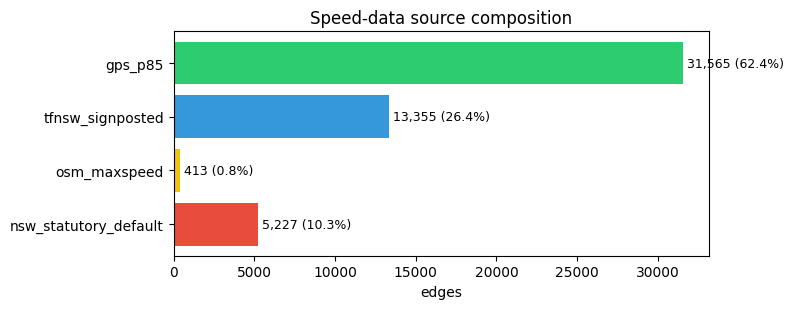

In [24]:
# Compute edge counts for each speed data source category
comp = edges["speed_source"].value_counts()
fig, ax = plt.subplots(figsize=(8,3.2))

# Define plotting order and corresponding hex color codes for each data source
order = ["gps_p85","tfnsw_signposted","osm_maxspeed","nsw_statutory_default"]
cols  = {"gps_p85":"#2ecc71","tfnsw_signposted":"#3498db","osm_maxspeed":"#f1c40f","nsw_statutory_default":"#e74c3c"}
vals  = [comp.get(o,0) for o in order]

# Render horizontal bar chart
ax.barh(order, vals, color=[cols[o] for o in order])

# Annotate each bar with the exact edge count and percentage share
for i,v in enumerate(vals):
    ax.text(v, i, f" {v:,} ({100*v/len(edges):.1f}%)", va="center", fontsize=9)

# Format axes labels, title, invert y-axis to display primary source at the top, and save figure
ax.set_xlabel("edges"); ax.set_title("Speed-data source composition")
ax.invert_yaxis(); plt.tight_layout()
plt.savefig(FIGURES/"01_speed_source_bar.png", dpi=150, bbox_inches="tight"); plt.show()

# D — Validation export

Stratified random samples (per class) of the key derived variables, with Google Street View audit links,
written to `validation_*.csv` for manual ground-truthing.


In [25]:
print("[D] Validation export...")

# Helper function to extract geographic coordinates from the midpoint of a line geometry
def _mid(geom):
    try: p = geom.interpolate(0.5, normalized=True); return p.y, p.x
    except Exception: return geom.centroid.y, geom.centroid.x

# Helper function to calculate the compass heading (azimuth) at the segment midpoint for Street View orientation
def _hdg(geom):
    try:
        a = geom.interpolate(0.45, normalized=True); b = geom.interpolate(0.55, normalized=True)
        return round(math.degrees(math.atan2(b.x-a.x, b.y-a.y)) % 360, 0)
    except Exception: return 0

# Helper function to construct a direct Google Maps Street View panorama URL using lat, lon, and heading
def _sv(lat, lon, h):
    return f"https://www.google.com/maps/@{lat:.6f},{lon:.6f},3a,75y,{h:.0f}h,85t/data=!3m6!1e1!3m4!1s!2e0!7i16384!8i8192"

VALIDATION_PER_GROUP = 10
VARIABLES_TO_VALIDATE = ["facility_type","parking","lane_category","speed_source"]

# Function to extract, stratify, and export validation samples for a given variable
def export_validation_sample(df, variable, n_per=VALIDATION_PER_GROUP, seed=VALIDATION_SEED):
    vals = sorted(df[variable].dropna().astype(str).unique())
    if not vals: print(f"  no values for {variable}"); return None
    parts = []
    
    # Stratified sampling: select up to n_per edges for each unique class of the variable
    for cls in vals:
        sub = df[df[variable].astype(str)==cls]
        if len(sub): parts.append(sub.sample(n=min(n_per,len(sub)), random_state=seed))
    out = pd.concat(parts).copy()
    
    # Reset multi-index if necessary to ensure clean tabular output
    if out.index.names == ["u","v","key"]: out = out.reset_index()
    
    # Compute spatial coordinates, headings, and Street View URLs
    coords = out.geometry.apply(_mid)
    out["lat"] = coords.apply(lambda c: c[0]); out["lon"] = coords.apply(lambda c: c[1])
    out["heading"] = out.geometry.apply(_hdg)
    out["streetview_url"] = out.apply(lambda r: _sv(r["lat"],r["lon"],r["heading"]), axis=1)
    
    # Initialise empty manual audit columns for human review
    out["observed_value"]=""; out["match"]=""; out["notes"]=""
    
    # Filter for relevant metadata columns
    keep = [c for c in ["u","v","key","name","highway",variable,"lanes","cycleway","maxspeed",
            "parallel_facility","osm_data_stale","lat","lon","heading","streetview_url",
            "observed_value","match","notes"] if c in out.columns]
            
    # Convert list-valued columns to strings to prevent CSV export formatting errors
    for c in keep:
        if out[c].dtype == object:
            out[c] = out[c].apply(lambda x: str(x[0]) if isinstance(x,list) else x)
            
    # Export stratified sample to CSV in the reports directory
    out[keep].to_csv(REPORTS/f"validation_{variable}.csv", index=False)
    print(f"  {variable:<16}{len(out):>3} links  ({len(vals)} classes x <= {n_per})  seed={seed}")
    return out[keep]

# Execute export loop across all designated validation variables
for v in VARIABLES_TO_VALIDATE:
    export_validation_sample(edges, v)
print(f"  Output dir: {REPORTS}")

[D] Validation export...
  facility_type    50 links  (5 classes x <= 10)  seed=42
  parking          30 links  (3 classes x <= 10)  seed=42
  lane_category    60 links  (6 classes x <= 10)  seed=42
  speed_source     40 links  (4 classes x <= 10)  seed=42
  Output dir: c:\Users\aylex\OneDrive - The University of Sydney (Students)\Thesis A\Python Code\Phase 1 + 2\reports


# E — Processed network export (hand-off to Notebook 02)

Writes `edges_with_variables.gpkg` with every derived attribute (list-valued columns sanitised) and prints
the hand-off summary for Notebooks 02 and 04.


In [26]:
print("[E] Export...")
var_export = edges.copy()

# Iterate through all columns to clean up list-valued cells before exporting to OGR/GeoPackage format
for c in var_export.columns:
    if c=="geometry": continue
    if var_export[c].dtype == object:
        var_export[c] = var_export[c].apply(lambda x: str(x[0]) if isinstance(x,list) else x)

# Define output path and export the processed network edges to a GeoPackage file
var_path = DATA_PROCESSED / "edges_with_variables.gpkg"
var_export.to_file(var_path, driver="GPKG")
print(f"  Saved: {var_path}")

# Print summary of exported columns and hand-off guidelines for Notebook 02 and Notebook 04
cols = [c for c in var_export.columns if c!="geometry"]
print(f"  Columns exported ({len(cols)}): {cols[:16]} ...")
print("\n  Hand-off to NB02:")
print(f"   - speed_kmh read against Furth NATIVE km/h columns {FURTH_KMH_EDGES}")
print( "   - adt + adt_source carry provenance; grade/grade_abs come from THIS notebook (A6)")
print( "   - NB04 routing: restrict to largest component -> ox.truncate.largest_component(G, strongly=False)")

[E] Export...
  Saved: c:\Users\aylex\OneDrive - The University of Sydney (Students)\Thesis A\Python Code\Phase 1 + 2\data\processed\edges_with_variables.gpkg
  Columns exported (81): ['osmid', 'highway', 'lanes', 'maxspeed', 'name', 'sidewalk', 'surface', 'oneway', 'reversed', 'length', 'bicycle', 'foot', 'segregated', 'width', 'cycleway:left', 'cycleway:left:lane'] ...

  Hand-off to NB02:
   - speed_kmh read against Furth NATIVE km/h columns [37.82, 45.87, 53.91, 61.96, 70.01, 78.05]
   - adt + adt_source carry provenance; grade/grade_abs come from THIS notebook (A6)
   - NB04 routing: restrict to largest component -> ox.truncate.largest_component(G, strongly=False)


# F — Assumptions register and completion

Compiles the methodological assumptions (CRS, speed hierarchy, ADT rules, parking, gradient, OSM vintage)
into `assumptions_register_01.txt` for audit traceability.


In [27]:
# Define the master assumptions list containing key parameter definitions and rules for Notebook 01
A = [
    ("CRS","EPSG:28356 (GDA94/MGA56); GDA2020 offset ~1.5-1.8 m below all thresholds."),
    ("Speed p85","GPS p85 = (p80+p90)/2; garbage rows and NaNs dropped; duplicates agg by '%s'." % SPEED_DUP_AGG),
    ("Speed bands","Furth v2.2 native: mph column edges x1.609344 -> %s km/h." % FURTH_KMH_EDGES),
    ("Speed priority","GPS p85 > TfNSW signposted > OSM maxspeed > NSW statutory default."),
    ("Speed-zone match","25 m buffer + >=30%% overlap; tie broken by greatest overlap."),
    ("One-way (bikes)","oneway:bicycle=no treated two-way for cyclists (contraflow)."),
    ("Centreline","TRUE only for class>=tertiary, or OSM-tagged 2+ lanes on a two-way."),
    ("Facility (link)","'%s'; separated parallel infra applied both directions." % FACILITY_LINK_RULE),
    ("Bike-lane width","untagged on-road lane = %.1f ft (reads narrow)." % DEFAULT_BIKE_LANE_WIDTH_FT),
    ("Parking","3-value yes/no/unknown from tags; untagged: residential/living/service/tertiary 'yes', secondary/primary/trunk 'no', other classes 'unknown'; unknown -> '%s' for LTS." % PARKING_UNKNOWN_AS),
    ("ADT hierarchy","on-link <=%d m > same-type <=%d m > class avg > Harvey." % (ADT_ON_LINK_M, ADT_SAME_TYPE_M)),
    ("ADT year/growth","most recent year per station, normalised to %d via '%s' growth (motor only)." % (ADT_REFERENCE_YEAR, ADT_GROWTH_METHOD)),
    ("Station scope","stations clipped to the SA1 CORDON (+buffer), not the LGA."),
    ("Gradient","rise/run from ELVIS 1 m bare-earth DEM; zeroed on steps, bridges, tunnels/covered ways and non-cyclable pedestrian links (rule '%s'); capped at 99.5th pct of >=5-cell edges." % GRADE_ZERO_RULE),
    ("OSM vintage","pinned snapshot %s (FORCE_REFRESH=%s)." % (OSM_SNAPSHOT, FORCE_REFRESH)),
    ("Network scope","all components retained here; NB04 routes on the largest component only."),
]

# Print formatted header and assumption items to the console
print("="*64 + "\nASSUMPTIONS REGISTER — Notebook 01\n" + "="*64)
for i,(k,v) in enumerate(A,1): print(f"{i:>2}. {k}: {v}")

# Export the complete assumptions register to a text file for reporting and verification
with open(REPORTS/"assumptions_register_01.txt","w",encoding="utf-8") as f:
    f.write("ASSUMPTIONS REGISTER — Notebook 01\n"+"="*60+"\n")
    for i,(k,v) in enumerate(A,1): f.write(f"{i:>2}. {k}: {v}\n")

print(f"\nSaved: {REPORTS/'assumptions_register_01.txt'}")
print("\nNOTEBOOK 01 — COMPLETE")

ASSUMPTIONS REGISTER — Notebook 01
 1. CRS: EPSG:28356 (GDA94/MGA56); GDA2020 offset ~1.5-1.8 m below all thresholds.
 2. Speed p85: GPS p85 = (p80+p90)/2; garbage rows and NaNs dropped; duplicates agg by 'max'.
 3. Speed bands: Furth v2.2 native: mph column edges x1.609344 -> [37.82, 45.87, 53.91, 61.96, 70.01, 78.05] km/h.
 4. Speed priority: GPS p85 > TfNSW signposted > OSM maxspeed > NSW statutory default.
 5. Speed-zone match: 25 m buffer + >=30%% overlap; tie broken by greatest overlap.
 6. One-way (bikes): oneway:bicycle=no treated two-way for cyclists (contraflow).
 7. Centreline: TRUE only for class>=tertiary, or OSM-tagged 2+ lanes on a two-way.
 8. Facility (link): 'direction_specific'; separated parallel infra applied both directions.
 9. Bike-lane width: untagged on-road lane = 5.0 ft (reads narrow).
10. Parking: 3-value yes/no/unknown from tags; untagged: residential/living/service/tertiary 'yes', secondary/primary/trunk 'no', other classes 'unknown'; unknown -> 'yes' for

In [28]:
# End-of-run key-results printout (recomputed from the finished `edges` table).
print("NOTEBOOK 01 - LTS INPUT VARIABLES: KEY RESULTS")
print("=" * 52)
print(f"Directed edges exported : {len(edges):,}")
print(f"Compass GPS speed layer : {'ON' if USE_COMPASS_SPEED else 'OFF'}")
print("Speed source share:")
for src, n in edges["speed_source"].value_counts().items():
    print(f"  {src:<22}{n:>7,}  ({100*n/len(edges):5.1f}%)")
print("Facility type:")
for fac, n in edges["facility_type"].value_counts().items():
    print(f"  {fac:<16}{n:>7,}")
_meas = edges["adt_source"].isin({"on_link", "nearby_same_type"}).sum()
_need = (~edges["adt_source"].eq("no_motor_traffic")).sum()
print(f"ADT measured on         : {_meas:,}/{_need:,} motor edges ({100*_meas/max(_need,1):.1f}%)")
print(f"Gradient |grade| p90/max: {edges['grade_abs'].quantile(0.90)*100:.2f}% / {edges['grade_abs'].max()*100:.2f}%")
print("Output: data/processed/edges_with_variables.gpkg  ->  Notebook 02")


NOTEBOOK 01 - LTS INPUT VARIABLES: KEY RESULTS
Directed edges exported : 50,560
Compass GPS speed layer : ON
Speed source share:
  gps_p85                31,565  ( 62.4%)
  tfnsw_signposted       13,355  ( 26.4%)
  nsw_statutory_default   5,227  ( 10.3%)
  osm_maxspeed              413  (  0.8%)
Facility type:
  mixed            35,909
  track             9,772
  excluded          4,051
  lane_with_park      772
  lane_no_park         56
ADT measured on         : 1,069/40,141 motor edges (2.7%)
Gradient |grade| p90/max: 6.07% / 16.00%
Output: data/processed/edges_with_variables.gpkg  ->  Notebook 02
